# Executed HUC12 example

This is the successful input-preparation run for **010801040205**. **NLCD-only exception:** verified previously downloaded NLCD rasters were used as explicit local inputs during the service outage. All other provider inputs were downloaded fresh. This is not an entirely fresh benchmark. Plots, timings and numerical results are from the real run. Machine-specific output paths are replaced with portable placeholders, and live-widget view references are omitted. Use `HUC12_Demo.ipynb` for the clean rerunnable notebook.

**The notebook prepared both configurations; it did not run the full four-month GPU spin-up or transient simulation.**

# Fresh HUC12 example — Lake Morey-Connecticut River

HUC **010801040205**, New Hampshire/Vermont; nominal 30 m USGS DEM and exact 30 m RIFT grid. The 48-hour event is **2023-07-10T00:00:00Z → 2023-07-12T00:00:00Z**.

This example exercises the updated front end: native downloads, land/soil/rainfall QC, observed event inflow, 20-year USGS low-flow history, four-calendar-month rain-free spin-up configuration, and a complete-hotstart transient configuration. Periodic hotstarts default ON; spin-up outputs are daily and event outputs hourly.

**Input preparation only:** Run All downloads and validates inputs and writes both CFGs. It does not execute four months of GPU simulation or calibrate a flood model. Read `examples/README.md` for the upstream-gauge approximation and boundary choices. The visible soil constants are user-approved illustrative replacements for missing processed cells; raw SSURGO is unchanged. No land-cover constants are preselected. Review the diagnostic maps and replacement counts before scientific use.

**Fresh mode:** Run All replaces only the package-marked case `demo_cases/demo_huc12_010801040205/` and downloads again. For another basin use `RIFT_Input_Builder.ipynb` and update the gauges/boundaries too.


## Imports and notebook display

In [1]:
%load_ext autoreload
%autoreload 2

import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import ipywidgets as widgets
from IPython.display import Image, JSON, Markdown, display

REPOSITORY_ROOT = next((
    folder for folder in (Path.cwd(), *Path.cwd().parents)
    if (folder / "pyproject.toml").is_file() and (folder / "riftprep").is_dir()
), None)
if REPOSITORY_ROOT is None:
    raise RuntimeError("Extract/clone the complete repository before opening this notebook.")
os.chdir(REPOSITORY_ROOT)
if str(REPOSITORY_ROOT) not in sys.path:
    sys.path.insert(0, str(REPOSITORY_ROOT))

from riftprep import RIFTInputBuilder, build_rift_inputs
from riftprep.notebook_frontend import (
    build_case_from_widget_values, simulation_duration_seconds, snapshot_widget_values,
    require_current_settings,
)

plt.rcParams["figure.figsize"] = (8, 6)
pd.options.display.max_colwidth = 120

SOURCE_CATALOG_PATH = Path("docs/rift_input_source_catalog.csv")
source_catalog = pd.read_csv(SOURCE_CATALOG_PATH)

# Only these reviewed catalog entries have executable adapters in this release.
# The complete catalog remains available in docs/ as a clearly separate roadmap.
SUPPORTED_CATALOG_KEYS = {
    "Study-area boundary": {"usgs_wbd", "local_vector", "coordinate_rectangle"},
    "Terrain DEM and coastal topobathymetry": {
        "usgs_3dep_10m", "usgs_3dep_30m", "copernicus_glo30", "local_raster",
    },
    "Initial water depth and restart state": {
        "dry_zero", "constant_depth", "local_depth_raster",
    },
    "Hydrography, channels, and outlets": {"usgs_3dhp", "local_vector"},
    "River/channel bathymetry and hydraulic geometry": {
        "constant_channel", "hydraulic_geometry",
    },
    "Land cover, imperviousness, canopy, and Manning roughness": {
        "nlcd", "local_rasters",
    },
    "Soil and infiltration properties": {"ssurgo", "soilgrids", "local_vector_or_rasters"},
    "Rainfall and meteorological forcing": {
        "aorc", "daymet", "mrms", "era5_land", "local_grids",
    },
    "River inflow hydrographs": {"usgs_waterdata", "usgs_nwis_legacy"},
    "Coastal water level and surge": {"usgs_waterdata_stage"},
    "Urban drainage and hydraulic controls": {
        "synthetic_nlcd", "local_vector", "local_raster",
    },
}


def show_source_options(category):
    """Show only executable choices; summarize future sources separately."""
    category_rows = source_catalog.loc[source_catalog["input_category"].eq(category)]
    supported = SUPPORTED_CATALOG_KEYS.get(category, set())
    selected = category_rows.loc[
        category_rows["provider_key"].isin(supported),
        ["provider_key", "source_name", "coverage_native_resolution", "status"],
    ]
    future = category_rows.loc[~category_rows["provider_key"].isin(supported)]
    display(Markdown("**Selectable now — every row below has an executable backend:**"))
    display(selected.reset_index(drop=True))
    if not future.empty:
        display(Markdown(
            f"*{len(future)} additional reviewed source(s) are documented in the "
            "roadmap but are intentionally not selectable until their adapters are tested.*"
        ))


def widget_box(*children):
    return widgets.VBox(list(children), layout=widgets.Layout(width="100%"))


WIDGET_STYLE = {"description_width": "220px"}


def download_and_show(name):
    """Download, gate, then show one accepted native product."""
    require_current_settings(widget_values, snapshot_widget_values(globals()))
    selected = getattr(spec, name)
    if not selected.enabled:
        display(Markdown(f"**{name}: disabled**"))
        return None
    print(f"Downloading {name} from {selected.provider}; selected source is unchanged.", flush=True)
    try:
        product = builder.download(name)
    except Exception:
        display(Markdown(f"### ⚠️ {name}: acquisition stopped — no product accepted"))
        display(Markdown(
            "Read the exception and saved provider diagnostics. A server failure does not "
            "mean that the selected CRS is wrong. Retry this download cell after recovery; "
            "to select local data, change its source widget and rebuild the managers."
        ))
        for diagnostic in sorted((builder.paths.raw / name / "service_diagnostics").glob("wms_health_*.json"))[-1:]:
            display(JSON(json.loads(diagnostic.read_text())))
        raise
    qc = builder.qc_result(name)
    display(Markdown(f"### ✅ {name}: `{qc.status}` — `{product.provider}`"))
    if (
        name == "hydrography"
        and product.metadata.get("empty_domain_confirmed")
        and int(product.metadata.get("features", -1)) == 0
    ):
        display(Markdown(
            "**No hydrography features were returned for the selected domain.** "
            "The provider confirmed an empty result; the raw empty vector is preserved "
            "and the workflow will skip automatic outlet carving. Provide coordinate "
            "outlets if your simulation requires an explicit outlet."
        ))
    display(pd.DataFrame(qc.checks))
    display(pd.DataFrame([
        {"artifact": key, "path": str(path), "bytes": path.stat().st_size}
        for key, path in product.files.items()
    ]))
    display(Markdown("**Saved, unchanged native product metadata**"))
    display(JSON(product.metadata))
    for figure in sorted(builder.paths.figures.glob(f"raw_{name}*")):
        if figure.suffix.lower() == ".png":
            display(Markdown("**QC-approved selected native product**"))
            display(Image(filename=str(figure)))
    return product

## Source availability

Only sources backed by executable, tested adapters appear in the selection widgets below. The
broader reviewed inventory remains in `docs/RIFT_INPUT_SOURCE_CATALOG.md` as a roadmap; those
entries are not presented as executable choices. Copernicus GLO-30, Daymet, MRMS, ERA5-Land,
and SoilGrids are included because they now have complete selection, download, normalization,
quality-control, plotting, and provenance paths.

In [2]:
supported_rows = []
for category, keys in SUPPORTED_CATALOG_KEYS.items():
    supported_rows.append(source_catalog.loc[
        source_catalog["input_category"].eq(category)
        & source_catalog["provider_key"].isin(keys)
    ])
available_now = pd.concat(supported_rows, ignore_index=True)
display(Markdown("### Executable source inventory"))
display(available_now)
display(Markdown(
    f"**{len(source_catalog) - len(available_now)} reviewed future source(s)** are retained "
    "in the documentation roadmap and intentionally excluded from the widgets."
))

### Executable source inventory

,input_category,provider_key,source_name,official_url,coverage_native_resolution,status,rift_conversion
0,Study-area boundary,usgs_wbd,USGS Watershed Boundary Dataset,https://www.usgs.gov/national-hydrography/watershed-boundary-dataset,"United States; HUC2–HUC12 complete, optional HUC14/HUC16",working,"Select HUC, dissolve, project, and rasterize masks"
1,Study-area boundary,local_vector,User SHP/GPKG/GeoJSON,NaN,Any valid polygon and CRS,working,"Validate, dissolve, project, and rasterize masks"
2,Study-area boundary,coordinate_rectangle,User bounds and CRS,NaN,Any rectangular study area,working,"Create polygon, project, and rasterize masks"
3,Terrain DEM and coastal topobathymetry,usgs_3dep_10m,USGS 3DEP 1/3 arc-second,https://www.usgs.gov/3d-elevation-program/about-3dep-products-services,U.S.; approximately 10 m seamless bare-earth DEM,working,Save returned WMS/py3dep dataset snapshot under raw; convert and align under processed
4,Terrain DEM and coastal topobathymetry,usgs_3dep_30m,USGS 3DEP 1 arc-second,https://www.usgs.gov/3d-elevation-program/about-3dep-products-services,U.S. and neighboring areas; approximately 30 m,working,Save returned WMS/py3dep dataset snapshot under raw; convert and align under processed
5,Terrain DEM and coastal topobathymetry,copernicus_glo30,Copernicus DEM GLO-30,https://dataspace.copernicus.eu/explore-data/data-collections/copernicus-contributing-missions/collections-descripti...,Global land; 30 m,working,"Save public COG tiles unchanged, mosaic, record native vertical reference, reproject"
6,Terrain DEM and coastal topobathymetry,local_raster,User GeoTIFF/NetCDF/ESRI ASCII,NaN,Any grid with CRS and elevation units,working,Validate units/datum and reproject
7,Initial water depth and restart state,dry_zero,Constant zero depth,NaN,Any domain,working / derived,Write zero initial-depth raster
8,Initial water depth and restart state,constant_depth,User constant,NaN,Any domain,working / derived,Fill active nodes with documented nonnegative depth
9,Initial water depth and restart state,local_depth_raster,User GeoTIFF,NaN,Any domain,working / local,"Reproject, clip, and validate finite nonnegative depth"


**57 reviewed future source(s)** are retained in the documentation roadmap and intentionally excluded from the widgets.

## 1 — Case, study area, RIFT grid, and cache

## ✏️ USER EDIT

Choose one domain mode. Unused HUC, polygon, or rectangle fields are ignored. The 3DEP product
resolution and RIFT grid resolution are independent. `fresh` deletes only a previously marked
case directory and downloads everything again; `reuse` keeps that case's saved raw products.

In [3]:
show_source_options("Study-area boundary")

CASE_NAME_WIDGET = widgets.Text(value='demo_huc12_010801040205', description="Case name", style=WIDGET_STYLE)
OUTPUT_ROOT_WIDGET = widgets.Text(value='demo_cases', description="Output root", style=WIDGET_STYLE)
CACHE_MODE_WIDGET = widgets.Dropdown(
    options=[("Fresh download", "fresh"), ("Reuse saved case data", "reuse")],
    value='fresh', description="Cache mode", style=WIDGET_STYLE,
)
CASE_CONFIG_OVERRIDE_WIDGET = widgets.Text(
    value="", description="Advanced YAML override", placeholder="Normally leave blank",
    style=WIDGET_STYLE,
)

DOMAIN_MODE_WIDGET = widgets.Dropdown(
    options=[("USGS HUC", "huc"), ("Local polygon", "shapefile"),
             ("Coordinate rectangle", "rectangle")],
    value="huc", description="Study-area mode", style=WIDGET_STYLE,
)
HUC_CODE_WIDGET = widgets.Text(value='010801040205', description="HUC code", style=WIDGET_STYLE)
HUC_LEVEL_WIDGET = widgets.Dropdown(
    options=[("Infer from code", None), *[(f"HUC {level}", level) for level in range(2, 18, 2)]],
    value=None, description="HUC level", style=WIDGET_STYLE,
)
SHAPEFILE_PATH_WIDGET = widgets.Text(value="", description="Polygon file", style=WIDGET_STYLE)
SHAPEFILE_LAYER_WIDGET = widgets.Text(value="", description="Polygon layer", style=WIDGET_STYLE)
RECTANGLE_XMIN_WIDGET = widgets.FloatText(value=-72.30, description="Rectangle xmin", style=WIDGET_STYLE)
RECTANGLE_YMIN_WIDGET = widgets.FloatText(value=41.60, description="Rectangle ymin", style=WIDGET_STYLE)
RECTANGLE_XMAX_WIDGET = widgets.FloatText(value=-72.15, description="Rectangle xmax", style=WIDGET_STYLE)
RECTANGLE_YMAX_WIDGET = widgets.FloatText(value=41.75, description="Rectangle ymax", style=WIDGET_STYLE)
RECTANGLE_CRS_WIDGET = widgets.Text(value="EPSG:4326", description="Rectangle CRS", style=WIDGET_STYLE)

TARGET_CRS_WIDGET = widgets.Text(value="EPSG:5070", description="RIFT target CRS", style=WIDGET_STYLE)
RIFT_GRID_RESOLUTION_WIDGET = widgets.FloatText(value=30.0, description="RIFT cell size (m)", style=WIDGET_STYLE)
DOWNLOAD_BUFFER_WIDGET = widgets.IntText(value=2, description="Download buffer (cells)", style=WIDGET_STYLE)
BOUNDARY_RULE_WIDGET = widgets.Dropdown(
    options=[("Cell center", "cell_center"), ("All touched", "all_touched"),
             ("Strict interior", "interior")],
    value="cell_center", description="Boundary rule", style=WIDGET_STYLE,
)
OUTSIDE_DEM_WIDGET = widgets.Dropdown(
    options=[("Closed wall", "wall"), ("Keep real terrain", "real_terrain")],
    value="wall", description="Outside-domain DEM", style=WIDGET_STYLE,
)
WALL_ELEVATION_WIDGET = widgets.FloatText(value=9999.0, description="Wall elevation (m)", style=WIDGET_STYLE)
RAW_PLOTS_WIDGET = widgets.Checkbox(value=True, description="Create raw-product plots", indent=False)
PROCESSED_PLOTS_WIDGET = widgets.Checkbox(value=True, description="Create final RIFT-product plots", indent=False)
PLOT_DPI_WIDGET = widgets.IntText(value=110, description="Plot DPI", style=WIDGET_STYLE)

display(widget_box(
    CASE_NAME_WIDGET, OUTPUT_ROOT_WIDGET, CACHE_MODE_WIDGET, CASE_CONFIG_OVERRIDE_WIDGET,
    DOMAIN_MODE_WIDGET, HUC_CODE_WIDGET, HUC_LEVEL_WIDGET,
    SHAPEFILE_PATH_WIDGET, SHAPEFILE_LAYER_WIDGET,
    RECTANGLE_XMIN_WIDGET, RECTANGLE_YMIN_WIDGET,
    RECTANGLE_XMAX_WIDGET, RECTANGLE_YMAX_WIDGET, RECTANGLE_CRS_WIDGET,
    TARGET_CRS_WIDGET, RIFT_GRID_RESOLUTION_WIDGET, DOWNLOAD_BUFFER_WIDGET,
    BOUNDARY_RULE_WIDGET, OUTSIDE_DEM_WIDGET, WALL_ELEVATION_WIDGET,
    widgets.HBox([RAW_PLOTS_WIDGET, PROCESSED_PLOTS_WIDGET]), PLOT_DPI_WIDGET,
))

**Selectable now — every row below has an executable backend:**

,provider_key,source_name,coverage_native_resolution,status
0,usgs_wbd,USGS Watershed Boundary Dataset,"United States; HUC2–HUC12 complete, optional HUC14/HUC16",working
1,local_vector,User SHP/GPKG/GeoJSON,Any valid polygon and CRS,working
2,coordinate_rectangle,User bounds and CRS,Any rectangular study area,working


*3 additional reviewed source(s) are documented in the roadmap but are intentionally not selectable until their adapters are tested.*

## 2 — Terrain DEM

## ✏️ USER EDIT

Choose USGS 3DEP 10/30 m, public Copernicus GLO-30, or a local raster. The returned 3DEP service
dataset, unchanged Copernicus COG tiles, or a byte-preserved local copy is saved under `raw/`
before riftprep converts, mosaics, or aligns it. Derived DEMs are written under `processed/`;
Copernicus elevations retain their provider vertical reference for datum review.

In [4]:
show_source_options("Terrain DEM and coastal topobathymetry")

DEM_SOURCE_WIDGET = widgets.Dropdown(
    options=[("USGS 3DEP service product — 30 m", "3dep_30"),
             ("USGS 3DEP service product — 10 m", "3dep_10"),
             ("Copernicus DEM GLO-30 — 30 m COG tiles", "copernicus_glo30"),
             ("Local raster", "local")],
    value="3dep_30", description="DEM source", style=WIDGET_STYLE,
)
DEM_LOCAL_PATH_WIDGET = widgets.Text(value="", description="Local DEM path", style=WIDGET_STYLE)
DEM_TILE_DEGREES_WIDGET = widgets.FloatText(value=0.5, description="Tile size (degrees)", style=WIDGET_STYLE)
DEM_MAX_ATTEMPTS_WIDGET = widgets.IntText(value=8, description="Download attempts", style=WIDGET_STYLE)
display(widget_box(
    DEM_SOURCE_WIDGET, DEM_LOCAL_PATH_WIDGET,
    DEM_TILE_DEGREES_WIDGET, DEM_MAX_ATTEMPTS_WIDGET,
))

**Selectable now — every row below has an executable backend:**

,provider_key,source_name,coverage_native_resolution,status
0,usgs_3dep_10m,USGS 3DEP 1/3 arc-second,U.S.; approximately 10 m seamless bare-earth DEM,working
1,usgs_3dep_30m,USGS 3DEP 1 arc-second,U.S. and neighboring areas; approximately 30 m,working
2,copernicus_glo30,Copernicus DEM GLO-30,Global land; 30 m,working
3,local_raster,User GeoTIFF/NetCDF/ESRI ASCII,Any grid with CRS and elevation units,working


*7 additional reviewed source(s) are documented in the roadmap but are intentionally not selectable until their adapters are tested.*

## 3 — Initial water depth

## ✏️ USER EDIT

Choose a dry domain, one nonnegative constant depth, or a local depth raster. The selected
definition/raster is saved first, checked, converted to the RIFT grid, and plotted after QC.

In [5]:
show_source_options("Initial water depth and restart state")

INITIAL_SOURCE_WIDGET = widgets.Dropdown(
    options=[("Dry domain — zero depth", "dry_zero"),
             ("Uniform constant depth", "constant"),
             ("Local depth raster", "local")],
    value="dry_zero", description="Initial-state source", style=WIDGET_STYLE,
)
INITIAL_DEPTH_WIDGET = widgets.FloatText(value=0.0, description="Constant depth (m)", style=WIDGET_STYLE)
INITIAL_LOCAL_PATH_WIDGET = widgets.Text(value="", description="Local depth path", style=WIDGET_STYLE)
INITIAL_RESAMPLING_WIDGET = widgets.Dropdown(
    options=["bilinear", "nearest", "average"], value="bilinear",
    description="Local resampling", style=WIDGET_STYLE,
)
display(widget_box(
    INITIAL_SOURCE_WIDGET, INITIAL_DEPTH_WIDGET,
    INITIAL_LOCAL_PATH_WIDGET, INITIAL_RESAMPLING_WIDGET,
))

**Selectable now — every row below has an executable backend:**

,provider_key,source_name,coverage_native_resolution,status
0,dry_zero,Constant zero depth,Any domain,working / derived
1,constant_depth,User constant,Any domain,working / derived
2,local_depth_raster,User GeoTIFF,Any domain,working / local


*2 additional reviewed source(s) are documented in the roadmap but are intentionally not selectable until their adapters are tested.*

## 4 — Hydrography and channels

## ✏️ USER EDIT

In [6]:
show_source_options("Hydrography, channels, and outlets")

HYDRO_ENABLED_WIDGET = widgets.Checkbox(value=True, description="Enable hydrography", indent=False)
HYDRO_SOURCE_WIDGET = widgets.Dropdown(
    options=[("USGS 3DHP", "usgs_3dhp"), ("Local line vector", "local")],
    value="usgs_3dhp", description="Hydrography source", style=WIDGET_STYLE,
)
HYDRO_LOCAL_PATH_WIDGET = widgets.Text(value="", description="Local flowline path", style=WIDGET_STYLE)
HYDRO_TILE_DEGREES_WIDGET = widgets.FloatText(value=1.0, description="Tile size (degrees)", style=WIDGET_STYLE)
HYDRO_WORKERS_WIDGET = widgets.IntText(value=4, description="Download workers", style=WIDGET_STYLE)
display(widget_box(
    HYDRO_ENABLED_WIDGET, HYDRO_SOURCE_WIDGET, HYDRO_LOCAL_PATH_WIDGET,
    HYDRO_TILE_DEGREES_WIDGET, HYDRO_WORKERS_WIDGET,
))

**Selectable now — every row below has an executable backend:**

,provider_key,source_name,coverage_native_resolution,status
0,usgs_3dhp,USGS 3D Hydrography Program,U.S.; current web service and annual downloads,working
1,local_vector,User SHP/GPKG/GeoJSON,Any line network with CRS,working


*5 additional reviewed source(s) are documented in the roadmap but are intentionally not selectable until their adapters are tested.*

## 4b — Optional river bathymetry

## ✏️ USER EDIT

Bathymetry is derived from the selected hydrography and the explicit rules below. The final
burned DEM is quality-checked and plotted; no hidden watershed-specific depth is used.

In [7]:
show_source_options("River/channel bathymetry and hydraulic geometry")

BATHY_ENABLED_WIDGET = widgets.Checkbox(value=False, description="Burn channel bathymetry", indent=False)
BATHY_DEPTH_METHOD_WIDGET = widgets.Dropdown(
    options=[("Constant", "constant"), ("Vector attribute", "attribute"),
             ("Stream-order lookup", "stream_order")],
    value="constant", description="Depth method", style=WIDGET_STYLE,
)
BATHY_DEPTH_WIDGET = widgets.FloatText(value=1.5, description="Default depth (m)", style=WIDGET_STYLE)
BATHY_DEPTH_FIELD_WIDGET = widgets.Text(value="", description="Depth attribute", style=WIDGET_STYLE)
BATHY_ORDER_FIELD_WIDGET = widgets.Text(value="", description="Stream-order attribute", style=WIDGET_STYLE)
BATHY_DEPTH_BY_ORDER_WIDGET = widgets.Textarea(
    value="{}", description="Depth by order (JSON)", style=WIDGET_STYLE,
    layout=widgets.Layout(width="100%", height="70px"),
)
BATHY_WIDTH_METHOD_WIDGET = widgets.Dropdown(
    options=[("Constant", "constant"), ("Vector attribute", "attribute")],
    value="constant", description="Width method", style=WIDGET_STYLE,
)
BATHY_WIDTH_WIDGET = widgets.FloatText(value=30.0, description="Default width (m)", style=WIDGET_STYLE)
BATHY_WIDTH_FIELD_WIDGET = widgets.Text(value="", description="Width attribute", style=WIDGET_STYLE)
BATHY_SECTION_WIDGET = widgets.Dropdown(
    options=[("Gaussian", "gaussian"), ("Flat", "flat"), ("V-shaped", "v")],
    value="gaussian", description="Cross section", style=WIDGET_STYLE,
)
BATHY_PRESERVE_WIDGET = widgets.Checkbox(value=True, description="Preserve lower existing terrain", indent=False)
BATHY_MONOTONIC_WIDGET = widgets.Checkbox(value=False, description="Enforce downstream monotonicity", indent=False)
BATHY_DIRECTION_WIDGET = widgets.Dropdown(
    options=["north", "south", "east", "west"], value="south",
    description="Downstream direction", style=WIDGET_STYLE,
)
BATHY_MIN_SLOPE_WIDGET = widgets.FloatText(
    value=0.0, description="Minimum downstream slope", style=WIDGET_STYLE,
)
display(widget_box(
    BATHY_ENABLED_WIDGET, BATHY_DEPTH_METHOD_WIDGET, BATHY_DEPTH_WIDGET,
    BATHY_DEPTH_FIELD_WIDGET, BATHY_ORDER_FIELD_WIDGET, BATHY_DEPTH_BY_ORDER_WIDGET,
    BATHY_WIDTH_METHOD_WIDGET, BATHY_WIDTH_WIDGET, BATHY_WIDTH_FIELD_WIDGET,
    BATHY_SECTION_WIDGET, BATHY_PRESERVE_WIDGET, BATHY_MONOTONIC_WIDGET,
    BATHY_DIRECTION_WIDGET, BATHY_MIN_SLOPE_WIDGET,
))

**Selectable now — every row below has an executable backend:**

,provider_key,source_name,coverage_native_resolution,status
0,hydraulic_geometry,3DHP/NHDPlus drainage attributes plus user equations,Network dependent,derived
1,constant_channel,Hydrography plus user width/depth,Any mapped network,working


*5 additional reviewed source(s) are documented in the roadmap but are intentionally not selectable until their adapters are tested.*

## 5 — Land cover, imperviousness, canopy, and Manning roughness

## ✏️ USER EDIT

Downloaded NLCD remains untouched. In the processing copy, documented canopy flags `254`
(non-processing area) and `255` (background) are masked before reprojection so they cannot be
mixed into percentages. Any finite processed imperviousness or canopy value above 100% is
reported and capped to exactly 100% without changing the downloaded raw file. The notebook saves
a black flagged-cell map before this correction and a second map of the corrected percentage
products. Unsupported or non-integer cover classes are counted, marked null only in the
processing copy, and displayed in black on the full-area coverage map. Remaining null or
negative cells require an explicit supported cover class/constant or corrected local raster.

The online adapter selects **legacy NLCD 2021**, not the separate Annual NLCD series. Provider
HTTP failures have bounded retries and saved response evidence. A service outage never silently
changes the source or reuses another case; to use verified prior downloads, select **Local** and
provide all three rasters with their original CRS and coverage.

In [8]:
show_source_options("Land cover, imperviousness, canopy, and Manning roughness")

LAND_ENABLED_WIDGET = widgets.Checkbox(value=True, description="Enable land cover", indent=False)
LAND_SOURCE_WIDGET = widgets.Dropdown(
    options=[("Legacy NLCD — MRLC (2021 products)", "watershed_workflow_nlcd"),
             ("Local cover/impervious/canopy rasters", "local")],
    value="watershed_workflow_nlcd", description="Land-cover source", style=WIDGET_STYLE,
)
LAND_YEAR_WIDGET = widgets.IntText(value=2021, description="NLCD year", style=WIDGET_STYLE)
LAND_LOCATION_WIDGET = widgets.Text(value="L48", description="NLCD location", style=WIDGET_STYLE)
LAND_COVER_PATH_WIDGET = widgets.Text(value="", description="Local cover raster", style=WIDGET_STYLE)
LAND_IMPERVIOUS_PATH_WIDGET = widgets.Text(value="", description="Local impervious raster", style=WIDGET_STYLE)
LAND_CANOPY_PATH_WIDGET = widgets.Text(value="", description="Local canopy raster", style=WIDGET_STYLE)
LAND_TILE_DEGREES_WIDGET = widgets.FloatText(value=1.0, description="Tile size (degrees)", style=WIDGET_STYLE)
LAND_TILE_OVERLAP_WIDGET = widgets.FloatText(value=0.02, description="Tile overlap (degrees)", style=WIDGET_STYLE)
LAND_WORKERS_WIDGET = widgets.IntText(value=4, description="Download workers", style=WIDGET_STYLE)
LAND_ATTEMPTS_WIDGET = widgets.IntText(value=8, description="Download attempts", style=WIDGET_STYLE)
LAND_FILL_WIDGET = widgets.Textarea(
    value="{}", description="Missing-cell constants (JSON)", style=WIDGET_STYLE,
    placeholder='Example after reviewing the black map: {"cover": 43, "canopy": 50}',
    layout=widgets.Layout(width="100%", height="80px"),
)
LAND_DIMENSION_WIDGET = widgets.Textarea(
    value="{}", description="Malformed-dimension constants", style=WIDGET_STYLE,
    placeholder='Use only after reviewing a malformed source variable, e.g. {"cover": 43}',
    layout=widgets.Layout(width="100%", height="80px"),
)
display(widget_box(
    LAND_ENABLED_WIDGET, LAND_SOURCE_WIDGET, LAND_YEAR_WIDGET, LAND_LOCATION_WIDGET,
    LAND_COVER_PATH_WIDGET, LAND_IMPERVIOUS_PATH_WIDGET, LAND_CANOPY_PATH_WIDGET,
    LAND_TILE_DEGREES_WIDGET, LAND_TILE_OVERLAP_WIDGET,
    LAND_WORKERS_WIDGET, LAND_ATTEMPTS_WIDGET,
    LAND_FILL_WIDGET, LAND_DIMENSION_WIDGET,
))

**Selectable now — every row below has an executable backend:**

,provider_key,source_name,coverage_native_resolution,status
0,nlcd,Legacy NLCD 2021 / MRLC,"U.S.; 30 m legacy land cover, imperviousness, canopy products; distinct from Annual NLCD",working
1,local_rasters,User categorical cover plus optional impervious/canopy rasters,Any valid rasters,working


*9 additional reviewed source(s) are documented in the roadmap but are intentionally not selectable until their adapters are tested.*

## 6 — Soil and infiltration

## ✏️ USER EDIT

The notebook never guesses values for missing active soil cells. It first creates a black-cell
null map and pauses with **NEEDS USER INPUT**. After reviewing the map, provide constants only for
the missing properties or provide a corrected local product. SoilGrids downloads its original
250 m property layers and records the explicit pedotransfer conversion used to derive RIFT
hydraulic rasters. Residual-minus-porosity conflicts smaller than the explicit tolerance are
recorded as warnings without modifying either value.

In [9]:
show_source_options("Soil and infiltration properties")

SOIL_ENABLED_WIDGET = widgets.Checkbox(value=True, description="Enable soil/infiltration", indent=False)
SOIL_SOURCE_WIDGET = widgets.Dropdown(
    options=[("USDA SSURGO", "watershed_workflow_ssurgo"),
             ("ISRIC SoilGrids 2.0", "soilgrids"),
             ("Local soil polygon product", "local")],
    value="watershed_workflow_ssurgo", description="Soil source", style=WIDGET_STYLE,
)
SOIL_LOCAL_PATH_WIDGET = widgets.Text(value="", description="Local soil path", style=WIDGET_STYLE)
SOIL_INITIAL_SATURATION_WIDGET = widgets.FloatSlider(
    value=0.50, min=0.0, max=1.0, step=0.01,
    description="Initial saturation", style=WIDGET_STYLE, readout_format=".2f",
)
SOIL_TOLERANCE_WIDGET = widgets.FloatText(value=0.10, description="Residual−porosity tolerance", style=WIDGET_STYLE)
SOIL_ROOT_DEPTH_WIDGET = widgets.FloatText(value=0.50, description="Root depth (m)", style=WIDGET_STYLE)
SOIL_DRAINAGE_TIME_WIDGET = widgets.FloatText(value=172800, description="Drainage time (s)", style=WIDGET_STYLE)
SOIL_TILE_DEGREES_WIDGET = widgets.FloatText(value=0.25, description="Tile size (degrees)", style=WIDGET_STYLE)
SOIL_WORKERS_WIDGET = widgets.IntText(value=4, description="Download workers", style=WIDGET_STYLE)
SOIL_ATTEMPTS_WIDGET = widgets.IntText(value=8, description="Download attempts", style=WIDGET_STYLE)
SOIL_TIMEOUT_WIDGET = widgets.FloatText(value=120, description="Request timeout (s)", style=WIDGET_STYLE)
SOIL_SUBDIVISION_WIDGET = widgets.IntText(value=2, description="Subdivision depth", style=WIDGET_STYLE)
SOILGRIDS_DEPTH_WIDGET = widgets.Dropdown(
    options=["0-5cm", "5-15cm", "15-30cm", "30-60cm", "60-100cm", "100-200cm"],
    value="0-5cm", description="SoilGrids depth", style=WIDGET_STYLE,
)
SOILGRIDS_QUANTILE_WIDGET = widgets.Dropdown(
    options=[("Median", "Q0.5"), ("Mean", "mean"),
             ("5th percentile", "Q0.05"), ("95th percentile", "Q0.95")],
    value="Q0.5", description="SoilGrids statistic", style=WIDGET_STYLE,
)
SOIL_FILL_WIDGET = widgets.Textarea(
    value='{"permeability": 1e-12, "porosity": 0.42, "residual": 0.08, "alpha": 0.0002}', description="Missing-soil constants (JSON)", style=WIDGET_STYLE,
    placeholder='Example: {"permeability": 1e-12, "porosity": 0.42, "residual": 0.08, "alpha": 0.0002}',
    layout=widgets.Layout(width="100%", height="90px"),
)
display(widget_box(
    SOIL_ENABLED_WIDGET, SOIL_SOURCE_WIDGET, SOIL_LOCAL_PATH_WIDGET,
    SOIL_INITIAL_SATURATION_WIDGET, SOIL_TOLERANCE_WIDGET,
    SOIL_ROOT_DEPTH_WIDGET, SOIL_DRAINAGE_TIME_WIDGET,
    SOIL_TILE_DEGREES_WIDGET, SOIL_WORKERS_WIDGET, SOIL_ATTEMPTS_WIDGET,
    SOIL_TIMEOUT_WIDGET, SOIL_SUBDIVISION_WIDGET,
    SOILGRIDS_DEPTH_WIDGET, SOILGRIDS_QUANTILE_WIDGET, SOIL_FILL_WIDGET,
))

**Selectable now — every row below has an executable backend:**

,provider_key,source_name,coverage_native_resolution,status
0,ssurgo,USDA SSURGO / Soil Data Access,"Detailed U.S. soil map units, commonly 1:12,000–1:63,360",working
1,soilgrids,ISRIC SoilGrids,"Global; 250 m, six depth intervals",working
2,local_vector_or_rasters,User soil polygons or parameter rasters,Any valid user data,working


*7 additional reviewed source(s) are documented in the roadmap but are intentionally not selectable until their adapters are tested.*

## 7 — Rainfall forcing

## ✏️ USER EDIT

The provider responses are retained unchanged. AORC and MRMS provide hourly accumulation;
ERA5-Land cumulative fields are de-accumulated; Daymet daily totals require the visible, explicit
24-hour distribution assumption. With `uncovered_policy` set to `zero`, RIFT receives the source
forcing wherever it exists and zero precipitation only outside coverage. Coverage evidence is
still mapped in gray/black.

The simulation duration automatically equals **End UTC minus Start UTC** whenever rainfall is
enabled. Enter ISO timestamps with a timezone (`Z` means UTC). The preview updates as you edit;
the manager-build cell validates and saves the duration. For a simulation without rainfall,
disable rainfall and enter the separate duration in hours.

In [10]:
show_source_options("Rainfall and meteorological forcing")

RAIN_ENABLED_WIDGET = widgets.Checkbox(value=True, description="Enable rainfall", indent=False)
RAIN_SOURCE_WIDGET = widgets.Dropdown(
    options=[("NOAA AORC — hourly", "watershed_workflow_aorc"),
             ("ORNL Daymet V4 R1 — daily, explicitly distributed hourly", "daymet"),
             ("NOAA MRMS — hourly gauge-adjusted QPE", "mrms"),
             ("Copernicus ERA5-Land — hourly", "era5_land"),
             ("Local gridded NetCDF", "local")],
    value="watershed_workflow_aorc", description="Rainfall source", style=WIDGET_STYLE,
)
RAIN_LOCAL_PATH_WIDGET = widgets.Text(value="", description="Local rainfall path", style=WIDGET_STYLE)
RAIN_START_WIDGET = widgets.Text(value='2023-07-10T00:00:00Z', description="Start UTC", style=WIDGET_STYLE)
RAIN_END_WIDGET = widgets.Text(value='2023-07-12T00:00:00Z', description="End UTC", style=WIDGET_STYLE)
RAIN_VARIABLE_WIDGET = widgets.Text(value="APCP_surface", description="Precipitation variable", style=WIDGET_STYLE)
RAIN_POLICY_WIDGET = widgets.Dropdown(
    options=[("Zero outside source coverage", "zero"),
             ("Stop on any uncovered cell", "error")],
    value="zero", description="Uncovered-cell policy", style=WIDGET_STYLE,
)
RAIN_ATTEMPTS_WIDGET = widgets.IntText(value=8, description="Download attempts", style=WIDGET_STYLE)
SIMULATION_DURATION_HOURS_WIDGET = widgets.FloatText(
    value=24.0, description="Duration without rain (h)", style=WIDGET_STYLE,
)
SIMULATION_DURATION_PREVIEW = widgets.HTML()


def update_simulation_duration(change=None):
    SIMULATION_DURATION_HOURS_WIDGET.disabled = (
        RAIN_ENABLED_WIDGET.value
        or not globals().get("TRANSIENT_MATCH_RAINFALL_WIDGET", RAIN_ENABLED_WIDGET).value
    )
    try:
        seconds = simulation_duration_seconds(snapshot_widget_values(globals()))
        SIMULATION_DURATION_PREVIEW.value = (
            f"<b>Simulation duration:</b> {seconds / 3600:g} hours ({seconds:g} seconds). "
            "Event elapsed time starts at 0; with spin-up, the solver retains its restored clock. "
            "Rebuild the managers after changing settings."
        )
    except ValueError:
        SIMULATION_DURATION_PREVIEW.value = (
            "<b>Check the event times:</b> use timezone-aware ISO timestamps, with end "
            "after start; without rainfall, enter a positive duration."
        )


for control in (RAIN_ENABLED_WIDGET, RAIN_START_WIDGET, RAIN_END_WIDGET,
                SIMULATION_DURATION_HOURS_WIDGET):
    control.observe(update_simulation_duration, names="value")
update_simulation_duration()

DAYMET_DISTRIBUTION_WIDGET = widgets.Dropdown(
    options=[("Uniformly distribute each daily total over 24 UTC hours", "uniform_24h")],
    value="uniform_24h", description="Daymet time assumption", style=WIDGET_STYLE,
)
DAYMET_REGION_WIDGET = widgets.Dropdown(
    options=[("Continental North America", "na"), ("Hawaii", "hi"),
             ("Puerto Rico", "pr")],
    value="na", description="Daymet region", style=WIDGET_STYLE,
)
MRMS_PRODUCT_WIDGET = widgets.Dropdown(
    options=[("Gauge-adjusted hourly QPE Pass 2", "MultiSensor_QPE_01H_Pass2_00.00"),
             ("Gauge-adjusted hourly QPE Pass 1", "MultiSensor_QPE_01H_Pass1_00.00"),
             ("Radar-only hourly QPE", "RadarOnly_QPE_01H_00.00")],
    value="MultiSensor_QPE_01H_Pass2_00.00", description="MRMS product", style=WIDGET_STYLE,
)
MRMS_REGION_WIDGET = widgets.Dropdown(
    options=["CONUS", "ALASKA", "HAWAII", "CARIB"], value="CONUS",
    description="MRMS region", style=WIDGET_STYLE,
)
display(widget_box(
    RAIN_ENABLED_WIDGET, RAIN_SOURCE_WIDGET, RAIN_LOCAL_PATH_WIDGET,
    RAIN_START_WIDGET, RAIN_END_WIDGET, RAIN_VARIABLE_WIDGET,
    SIMULATION_DURATION_HOURS_WIDGET, SIMULATION_DURATION_PREVIEW,
    RAIN_POLICY_WIDGET, RAIN_ATTEMPTS_WIDGET,
    DAYMET_DISTRIBUTION_WIDGET, DAYMET_REGION_WIDGET,
    MRMS_PRODUCT_WIDGET, MRMS_REGION_WIDGET,
    widgets.HTML(
        "<i>Daymet requires NASA Earthdata authorization and ~/.netrc; ERA5-Land requires "
        "an accepted CDS licence and ~/.cdsapirc. MRMS needs cfgrib/ecCodes (included in "
        "environment.yml).</i>"
    ),
))

**Selectable now — every row below has an executable backend:**

,provider_key,source_name,coverage_native_resolution,status
0,aorc,NOAA AORC,"U.S.; about 1 km, hourly",working
1,mrms,NOAA MRMS,"U.S. radar domains; about 1 km, hourly QPE selected by this adapter",working
2,era5_land,Copernicus ERA5-Land,"Global land; about 9 km, hourly",working with CDS credentials
3,daymet,ORNL Daymet,"North America/Hawaii; 1 km, daily precipitation total",working with Earthdata credentials
4,local_grids,User NetCDF/GRIB/GeoTIFF/HDF5,Any supported gridded forcing,working


*7 additional reviewed source(s) are documented in the roadmap but are intentionally not selectable until their adapters are tested.*

## 8 — Optional inflow, coastal-stage, drainage, and outlet inputs

## ✏️ USER EDIT

Enable only the modules needed by the simulation and provide their explicit stations, controls,
or local files. Disabled managers are shown but are not called.

### Outlet choices

The outlet control is deliberately explicit:

- **Automatic lowest hydrography crossing** selects the lowest valid hydrography crossing of the
  study-area boundary. If the provider confirms that the domain has no hydrography, the notebook
  records that result and skips carving instead of inventing a river.
- **Outlet point/vector file** accepts a point Shapefile or GeoPackage. The file must contain a
  declared CRS; an optional `width_m` attribute can set the opening width for each point.
- **Explicit coordinates** accepts a JSON list such as
  `[{"x": 653939.5, "y": 1584239.8, "width_m": 120, "cut_elevation_m": 0}]`. The `x` and
  `y` values are in the CRS entered below (for example `EPSG:5070`); multiple objects create
  multiple outlets. `width_m` and `cut_elevation_m` are optional per-outlet overrides.
- **No outlet** leaves the closed wall unchanged.

Choose **Match terrain** to use the nearest valid active DEM elevation at each outlet, or choose
**Constant**, **Zero**, or **Sloped** to use the visible cut-elevation value. The optimized carving
routine rasterizes only the outlet-to-domain-edge corridor (or the local wall notch), so it does
not create full-domain coordinate or distance arrays.

In [11]:
show_source_options("River inflow hydrographs")
show_source_options("Coastal water level and surge")
show_source_options("Urban drainage and hydraulic controls")

INFLOW_ENABLED_WIDGET = widgets.Checkbox(value=True, description="Enable river inflows", indent=False)
INFLOW_SOURCE_WIDGET = widgets.Dropdown(
    options=[("Modern USGS Water Data API", "usgs_waterdata"),
             ("Legacy NWIS service", "usgs_nwis_legacy")],
    value="usgs_waterdata", description="Inflow source", style=WIDGET_STYLE,
)
INFLOW_START_WIDGET = widgets.Text(value='2023-07-10T00:00:00Z', description="Inflow start UTC", style=WIDGET_STYLE)
INFLOW_END_WIDGET = widgets.Text(value='2023-07-12T00:00:00Z', description="Inflow end UTC", style=WIDGET_STYLE)
INFLOW_STATIONS_WIDGET = widgets.Textarea(
    value='[{"site": "01138500", "id": "connecticut_inlet", "support": {"x": -72.1159051967093, "y": 43.99433661265048, "crs": "EPSG:4326"}, "support_width_m": 30}]', description="Inflow stations (JSON)", style=WIDGET_STYLE,
    placeholder='[{"site":"01184000","id":"inlet","support":{"x":-72.2,"y":41.7,"crs":"EPSG:4326"}}]',
    layout=widgets.Layout(width="100%", height="100px"),
)

COASTAL_ENABLED_WIDGET = widgets.Checkbox(value=False, description="Enable coastal stage", indent=False)
COASTAL_SOURCE_WIDGET = widgets.Dropdown(
    options=[("Modern USGS Water Data API", "usgs_waterdata")],
    value="usgs_waterdata", description="Coastal-stage source", style=WIDGET_STYLE,
)
COASTAL_START_WIDGET = widgets.Text(value="2023-06-10T00:00:00Z", description="Coastal start UTC", style=WIDGET_STYLE)
COASTAL_END_WIDGET = widgets.Text(value="2023-06-11T00:00:00Z", description="Coastal end UTC", style=WIDGET_STYLE)
COASTAL_INTERVAL_WIDGET = widgets.IntText(value=1, description="Surge interval (hours)", style=WIDGET_STYLE)
COASTAL_RADIUS_WIDGET = widgets.FloatText(value=3000.0, description="Coastal radius (m)", style=WIDGET_STYLE)
COASTAL_STATIONS_WIDGET = widgets.Textarea(
    value="[]", description="Coastal station (JSON)", style=WIDGET_STYLE,
    placeholder='[{"site":"station-id","datum_offset_m":0.0,"coastal_radius_m":3000}]',
    layout=widgets.Layout(width="100%", height="90px"),
)

DRAINAGE_ENABLED_WIDGET = widgets.Checkbox(value=False, description="Enable drainage", indent=False)
DRAINAGE_SOURCE_WIDGET = widgets.Dropdown(
    options=[("Synthetic from NLCD imperviousness", "synthetic_nlcd"),
             ("Local vector", "local_vector"), ("Local raster", "local_raster")],
    value="synthetic_nlcd", description="Drainage source", style=WIDGET_STYLE,
)
DRAINAGE_LOCAL_PATH_WIDGET = widgets.Text(value="", description="Local drainage path", style=WIDGET_STYLE)
DRAINAGE_THRESHOLD_WIDGET = widgets.FloatText(value=80.0, description="Impervious threshold (%)", style=WIDGET_STYLE)
DRAINAGE_CONTROLS_WIDGET = widgets.Textarea(
    value="[]", description="Hydraulic controls (JSON)", style=WIDGET_STYLE,
    placeholder="Required for local drainage; list rows with all 16 RIFT control fields",
    layout=widgets.Layout(width="100%", height="100px"),
)

OUTLET_SOURCE_WIDGET = widgets.Dropdown(
    options=[("Automatic lowest hydrography crossing", "auto_hydrography_lowest"),
             ("Outlet point/vector file", "vector"),
             ("Explicit coordinates", "coordinates"), ("No outlet", "none")],
    value='coordinates', description="Outlet rule", style=WIDGET_STYLE,
)
OUTLET_VECTOR_PATH_WIDGET = widgets.Text(
    value="", description="Outlet vector path", style=WIDGET_STYLE,
    placeholder="Point shapefile/GeoPackage with a declared CRS",
)
OUTLET_COORDINATES_WIDGET = widgets.Textarea(
    value='[{"x": -72.19999829322059, "y": 43.78764142565809, "width_m": 600}]', description="Outlet coordinates (JSON)", style=WIDGET_STYLE,
    placeholder='[{"x": 12345, "y": 67890, "width_m": 120, "cut_elevation_m": 0}]',
    layout=widgets.Layout(width="100%", height="80px"),
)
OUTLET_CRS_WIDGET = widgets.Text(value='EPSG:4326', description="Outlet coordinate CRS", style=WIDGET_STYLE)
OUTLET_METHOD_WIDGET = widgets.Dropdown(
    options=[("Open corridor", "open_corridor"), ("Wall notch", "wall_notch")],
    value="open_corridor", description="Outlet opening", style=WIDGET_STYLE,
)
OUTLET_ELEVATION_WIDGET = widgets.Dropdown(
    options=[("Match terrain", "terrain_matched"), ("Zero", "zero"),
             ("Constant", "constant"), ("Sloped", "sloped")],
    value="terrain_matched", description="Outlet elevation", style=WIDGET_STYLE,
)
OUTLET_WIDTH_WIDGET = widgets.FloatText(value=600, description="Outlet width (m)", style=WIDGET_STYLE)
OUTLET_CUT_ELEVATION_WIDGET = widgets.FloatText(
    value=0.0, description="Constant cut elevation (m)", style=WIDGET_STYLE,
)

display(widget_box(
    widgets.HTML("<b>River inflows</b>"), INFLOW_ENABLED_WIDGET,
    INFLOW_SOURCE_WIDGET, INFLOW_START_WIDGET, INFLOW_END_WIDGET, INFLOW_STATIONS_WIDGET,
    widgets.HTML("<b>Coastal stage</b>"), COASTAL_ENABLED_WIDGET,
    COASTAL_SOURCE_WIDGET, COASTAL_START_WIDGET, COASTAL_END_WIDGET,
    COASTAL_INTERVAL_WIDGET, COASTAL_RADIUS_WIDGET, COASTAL_STATIONS_WIDGET,
    widgets.HTML("<b>Drainage</b>"), DRAINAGE_ENABLED_WIDGET,
    DRAINAGE_SOURCE_WIDGET, DRAINAGE_LOCAL_PATH_WIDGET,
    DRAINAGE_THRESHOLD_WIDGET, DRAINAGE_CONTROLS_WIDGET,
    widgets.HTML("<b>Outlet</b>"), OUTLET_SOURCE_WIDGET,
    OUTLET_VECTOR_PATH_WIDGET,
    OUTLET_COORDINATES_WIDGET, OUTLET_CRS_WIDGET,
    OUTLET_METHOD_WIDGET, OUTLET_ELEVATION_WIDGET,
    OUTLET_CUT_ELEVATION_WIDGET, OUTLET_WIDTH_WIDGET,
))

**Selectable now — every row below has an executable backend:**

,provider_key,source_name,coverage_native_resolution,status
0,usgs_waterdata,Modern USGS Water Data APIs,"U.S. continuous observations, often 15 minute",working
1,usgs_nwis_legacy,USGS legacy-to-modern migration guide,U.S. legacy instantaneous/daily services,working / legacy


*4 additional reviewed source(s) are documented in the roadmap but are intentionally not selectable until their adapters are tested.*

**Selectable now — every row below has an executable backend:**

,provider_key,source_name,coverage_native_resolution,status
0,usgs_waterdata_stage,USGS Water Data APIs,Stage observations at available U.S. sites,working


*5 additional reviewed source(s) are documented in the roadmap but are intentionally not selectable until their adapters are tested.*

**Selectable now — every row below has an executable backend:**

,provider_key,source_name,coverage_native_resolution,status
0,synthetic_nlcd,Selected NLCD imperviousness,U.S. where NLCD is selected,working / derived
1,local_vector,User SHP/GPKG/GeoJSON,Any mapped drainage network,working
2,local_raster,User drainage-class raster,Any grid,working


*3 additional reviewed source(s) are documented in the roadmap but are intentionally not selectable until their adapters are tested.*

## ✏️ USER EDIT — transient time and output controls

By default the event matches the rainfall window above. To choose different dates, uncheck
**Match rainfall window**: these dates then control downloads of ALL enabled transient forcings.
UTC dates identify the real-world windows. The event's elapsed clock begins at zero, but a
hotstart continuation retains solver time and uses a forcing-origin offset. Save frequency
applies to depth, discharge, water-surface and hotstart outputs together.

In [12]:
TRANSIENT_MATCH_RAINFALL_WIDGET = widgets.Checkbox(
    value=True, description="Match rainfall window", indent=False)
TRANSIENT_START_WIDGET = widgets.Text(value="2023-06-10T00:00:00Z", description="Event start UTC", style=WIDGET_STYLE)
TRANSIENT_END_WIDGET = widgets.Text(value="2023-06-11T00:00:00Z", description="Event end UTC", style=WIDGET_STYLE)
TRANSIENT_OUTPUT_HOURS_WIDGET = widgets.FloatText(value=1.0, description="Save every (hours)", style=WIDGET_STYLE)
TRANSIENT_SAVE_HOTSTART_WIDGET = widgets.Checkbox(value=True, description="Save periodic transient hotstarts", indent=False)
TRANSIENT_OUTPUT_DIRECTORY_WIDGET = widgets.Text(value="results/transient", description="Event output folder", style=WIDGET_STYLE)

def update_event_controls(change=None):
    match = TRANSIENT_MATCH_RAINFALL_WIDGET.value and RAIN_ENABLED_WIDGET.value
    TRANSIENT_START_WIDGET.disabled = match
    TRANSIENT_END_WIDGET.disabled = TRANSIENT_MATCH_RAINFALL_WIDGET.value
    if match:
        TRANSIENT_START_WIDGET.value = RAIN_START_WIDGET.value
        TRANSIENT_END_WIDGET.value = RAIN_END_WIDGET.value
    elif TRANSIENT_MATCH_RAINFALL_WIDGET.value:
        from datetime import timedelta
        from riftprep.spinup import utc_time
        try:
            TRANSIENT_END_WIDGET.value = (utc_time(TRANSIENT_START_WIDGET.value)
                + timedelta(hours=SIMULATION_DURATION_HOURS_WIDGET.value)).isoformat()
        except (ValueError, OverflowError):
            pass
    update_simulation_duration()

for control in (TRANSIENT_MATCH_RAINFALL_WIDGET, RAIN_START_WIDGET, RAIN_END_WIDGET,
                RAIN_ENABLED_WIDGET, TRANSIENT_START_WIDGET, SIMULATION_DURATION_HOURS_WIDGET):
    control.observe(update_event_controls, names="value")
update_event_controls()
for control in (TRANSIENT_START_WIDGET, TRANSIENT_END_WIDGET):
    control.observe(update_simulation_duration, names="value")
display(widget_box(TRANSIENT_MATCH_RAINFALL_WIDGET, TRANSIENT_START_WIDGET,
                 TRANSIENT_END_WIDGET, TRANSIENT_OUTPUT_HOURS_WIDGET,
                 TRANSIENT_SAVE_HOTSTART_WIDGET, TRANSIENT_OUTPUT_DIRECTORY_WIDGET))

## ✏️ USER EDIT — rain-free spin-up and historical baseflow

Enable the two-stage run to create **rift_spinup.cfg + rift_case.cfg**. The default spin-up
window is four calendar months immediately before the event, with **daily output** and
**hotstart ON**. Uncheck the automatic window to enter your own start/end (end must equal event start).

Choose **USGS historical daily mean** to download the preceding **20 years** for your explicit
gauges and derive a constant hydrograph for each river boundary. Quantile is a non-exceedance
probability: **0 = observed minimum**, 0.05 = fifth percentile, 0.5 = median. It is NOT a guarantee
of perennial flow or separated groundwater baseflow. Genuine zeros remain zero. Missing/invalid
days are excluded without filling; default minimum record coverage is 90% and is reported.

The station JSON uses the same `site`, `id`, and optional `support`/`support_width_m` as transient
inflows. A gauge is NOT an automatically valid upstream boundary: choose non-overlapping inlet
catchments and review placement. No ungauged or area-scaled inflow is invented. Alternatively
choose **User constant**, with `constant_m3_s` and explicit support coordinates.

Example historical station (replace site and support for your domain):
`[{"site":"01184000","id":"inlet","support":{"x":-72.2,"y":41.7,"crs":"EPSG:4326"}}]`

Example manual station:
`[{"id":"inlet","constant_m3_s":0.2,"support":{"x":-72.2,"y":41.7,"crs":"EPSG:4326"}}]`

No rainfall is acquired for spin-up. The selected constant has two endpoints spanning its whole
duration. **Complete hotstart continuation:** momentum, infiltration history, soil saturation and
urban storage are retained without resampling. A checkpoint at the EXACT spin-up end is mandatory
even when periodic hotstarts are off. Event diagnostic statistics are reset, not physical state.
This requires the supplied RIFT-UConn complete-restart integration; an unpatched solver is rejected.
Read `integrations/rift_uconn/README.md` and the generated RUN.md before simulation.

In [13]:
SPINUP_ENABLED_WIDGET = widgets.Checkbox(value=True, description="Prepare spin-up + transient CFGs", indent=False)
SPINUP_AUTO_WINDOW_WIDGET = widgets.Checkbox(value=True, description="Four calendar months before event", indent=False)
SPINUP_START_WIDGET = widgets.Text(value="2023-02-10T00:00:00Z", description="Spin-up start UTC", style=WIDGET_STYLE)
SPINUP_END_WIDGET = widgets.Text(value="2023-06-10T00:00:00Z", description="Spin-up end UTC", style=WIDGET_STYLE)
SPINUP_SOURCE_WIDGET = widgets.Dropdown(
    options=[("USGS historical daily mean — quantile", "usgs_waterdata"),
             ("User constant (m³/s)", "manual_constant")], value="usgs_waterdata",
    description="Baseflow method", style=WIDGET_STYLE)
SPINUP_USE_INFLOW_STATIONS_WIDGET = widgets.Checkbox(value=True, description="Use transient inflow station list", indent=False)
SPINUP_STATIONS_WIDGET = widgets.Textarea(value='[{"site": "01138500", "id": "connecticut_inlet", "support": {"x": -72.1159051967093, "y": 43.99433661265048, "crs": "EPSG:4326"}, "support_width_m": 30}]', description="Spin-up stations JSON", style=WIDGET_STYLE,
    layout=widgets.Layout(width="100%", height="100px"))
SPINUP_HISTORY_YEARS_WIDGET = widgets.IntText(value=20, description="History (years)", style=WIDGET_STYLE)
SPINUP_QUANTILE_WIDGET = widgets.BoundedFloatText(value=0, min=0, max=1, step=0.001,
    description="Flow quantile (0–1)", style=WIDGET_STYLE)
SPINUP_MINIMUM_COVERAGE_WIDGET = widgets.FloatSlider(value=0.9, min=0.01, max=1, step=0.01,
    description="Minimum valid-day fraction", readout_format=".2f", style=WIDGET_STYLE)
SPINUP_OUTPUT_HOURS_WIDGET = widgets.FloatText(value=24.0, description="Save every (hours)", style=WIDGET_STYLE)
SPINUP_SAVE_HOTSTART_WIDGET = widgets.Checkbox(value=True, description="Save periodic spin-up hotstarts", indent=False)
SPINUP_OUTPUT_DIRECTORY_WIDGET = widgets.Text(value="results/spinup", description="Spin-up output folder", style=WIDGET_STYLE)

def update_spinup_controls(change=None):
    from riftprep.spinup import calendar_shift
    automatic = SPINUP_AUTO_WINDOW_WIDGET.value
    SPINUP_START_WIDGET.disabled = SPINUP_END_WIDGET.disabled = automatic
    SPINUP_STATIONS_WIDGET.disabled = SPINUP_USE_INFLOW_STATIONS_WIDGET.value
    if automatic:
        try:
            SPINUP_END_WIDGET.value = TRANSIENT_START_WIDGET.value
            SPINUP_START_WIDGET.value = calendar_shift(SPINUP_END_WIDGET.value, months=-4)
        except ValueError:
            pass  # The manager-build cell reports invalid calendar dates.

for control in (SPINUP_AUTO_WINDOW_WIDGET, TRANSIENT_START_WIDGET, SPINUP_USE_INFLOW_STATIONS_WIDGET):
    control.observe(update_spinup_controls, names="value")
update_spinup_controls()
display(widget_box(SPINUP_ENABLED_WIDGET, SPINUP_AUTO_WINDOW_WIDGET, SPINUP_START_WIDGET,
    SPINUP_END_WIDGET, SPINUP_SOURCE_WIDGET, SPINUP_USE_INFLOW_STATIONS_WIDGET,
    SPINUP_STATIONS_WIDGET, SPINUP_HISTORY_YEARS_WIDGET, SPINUP_QUANTILE_WIDGET,
    SPINUP_MINIMUM_COVERAGE_WIDGET, SPINUP_OUTPUT_HOURS_WIDGET,
    SPINUP_SAVE_HOTSTART_WIDGET, SPINUP_OUTPUT_DIRECTORY_WIDGET))

## Build and log the source managers

This is analogous to Watershed Workflow's source-manager setup cell. It validates the choices,
saves a reusable YAML configuration, initializes the case-local data directory, and displays
exactly which manager will provide each input. After changing any control, rerun this cell and
the domain/download cells; the notebook checks for stale settings before continuing.

### Explicit NLCD-only reuse for this validation run

The selected legacy NLCD service is unavailable. The user approved reusing its previously downloaded 2021 rasters, verified against their original SHA-256 catalog. They are copied unchanged, and active-cell coverage is checked during processing. Every other input is downloaded fresh. The clean demo keeps the online source as default.

In [14]:
LAND_SOURCE_WIDGET.value = "local"
LAND_COVER_PATH_WIDGET.value = "demo_inputs/preserved_nlcd/nlcd_cover_2021_native.tif"
LAND_IMPERVIOUS_PATH_WIDGET.value = "demo_inputs/preserved_nlcd/nlcd_impervious_2021_native.tif"
LAND_CANOPY_PATH_WIDGET.value = "demo_inputs/preserved_nlcd/nlcd_canopy_2021_native.tif"
display(JSON(json.loads(Path("demo_inputs/preserved_nlcd/reuse_receipt.json").read_text())))

<IPython.core.display.JSON object>

In [15]:
widget_values = snapshot_widget_values(globals())
spec, config_path, override_used = build_case_from_widget_values(
    widget_values, environment=os.environ
)
builder = RIFTInputBuilder(spec)

display(Markdown(
    f"**Saved configuration:** `{config_path}`  \
"
    f"**Case directory:** `{spec.case_root}`  \
"
    f"**Cache mode:** `{spec.cache.mode}`  \
"
    f"**Configuration override used:** `{override_used}`"
))
display(builder.source_table())
display(Markdown(
    f"**Simulation duration:** "
    f"{spec.simulation.end_time_s - spec.simulation.start_time_s:g} seconds "
    f"({(spec.simulation.end_time_s - spec.simulation.start_time_s) / 3600:g} hours)"
))
if spec.spinup.enabled:
    display(JSON({"spinup_start_utc": spec.spinup.start_utc,
                  "spinup_end_utc": spec.spinup.end_utc,
                  "duration_days": spec.spinup.duration_s / 86400,
                  "baseflow_history_request": spec.spinup.download_options(),
                  "spinup_output_interval_s": spec.spinup.output_interval_s,
                  "spinup_hotstart": spec.spinup.save_hotstart,
                  "transient_output_interval_s": spec.simulation.output_interval_s,
                  "transient_hotstart": spec.simulation.save_hotstart}))

**Saved configuration:** `generated_configs/demo_huc12_010801040205.yaml`  **Case directory:** `demo_cases/demo_huc12_010801040205`  **Cache mode:** `fresh`  **Configuration override used:** `False`

,input,enabled,provider,selected_options
0,dem,True,watershed_workflow_3dep,"{""max_attempts"": 8, ""resolution_m"": 30, ""tile_degrees"": 0.5}"
1,initial_state,True,dry_zero,{}
2,hydrography,True,usgs_3dhp,"{""download_workers"": 4, ""tile_degrees"": 1.0}"
3,land_cover,True,local,"{""manual_dimension_constants"": {}, ""manual_fill_values"": {}, ""rasters"": {""canopy"": ""demo_inputs/preserved_nlcd/nlcd_..."
4,soil,True,watershed_workflow_ssurgo,"{""download_workers"": 4, ""drainage_time_s"": 172800.0, ""initial_saturation"": 0.5, ""manual_fill_values"": {""alpha"": 0.00..."
5,rainfall,True,watershed_workflow_aorc,"{""end_utc"": ""2023-07-12T00:00:00Z"", ""max_attempts"": 8, ""precipitation_variable"": ""APCP_surface"", ""start_utc"": ""2023-..."
6,drainage,False,synthetic_nlcd,"{""impervious_threshold_pct"": 80.0}"
7,inflows,True,usgs_waterdata,"{""end_utc"": ""2023-07-12T00:00:00Z"", ""start_utc"": ""2023-07-10T00:00:00Z"", ""stations"": [{""id"": ""connecticut_inlet"", ""s..."
8,coastal,False,usgs_waterdata,"{""coastal_radius_m"": 3000.0, ""end_utc"": ""2023-06-11T00:00:00Z"", ""interval_hours"": 1, ""start_utc"": ""2023-06-10T00:00:..."
9,spinup_baseflow,True,usgs_waterdata,"{""collection"": ""daily"", ""end_utc"": ""2023-03-09T23:59:59Z"", ""history_years"": 20, ""minimum_coverage"": 0.9, ""quantile"":..."


**Simulation duration:** 172800 seconds (48 hours)

<IPython.core.display.JSON object>

## Domain manager: load and display the study area

In [16]:
require_current_settings(widget_values, snapshot_widget_values(globals()))
boundary = builder.load_domain()
grid = builder.grid

ax = boundary.to_crs(grid.crs).plot(facecolor="none", edgecolor="black", linewidth=1.2)
ax.set(title=f"Selected study area — {spec.domain.mode}", xlabel="Easting (m)", ylabel="Northing (m)")
plt.show()
display(JSON(grid.as_dict()))

<IPython.core.display.JSON object>

## DEM manager: preserve, checksum, and display the selected source DEM

### ✅ dem: `PASSED` — `watershed_workflow_3dep`

,check,status,value
0,saved native artifacts or declared derivation,PASS,2
1,provider_response: saved and nonempty,PASS,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...
2,raster: saved and nonempty,PASS,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...
3,DEM: readable raster,PASS,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...
4,DEM: CRS declared,PASS,EPSG:5070
5,DEM: positive dimensions,PASS,"[1172, 1099]"
6,DEM: contains valid cells,PASS,175717


,artifact,path,bytes
0,provider_response,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...,5191279
1,raster,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...,2927122
2,plot,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...,240338


**Saved, unchanged native product metadata**

<IPython.core.display.JSON object>

**QC-approved selected native product**

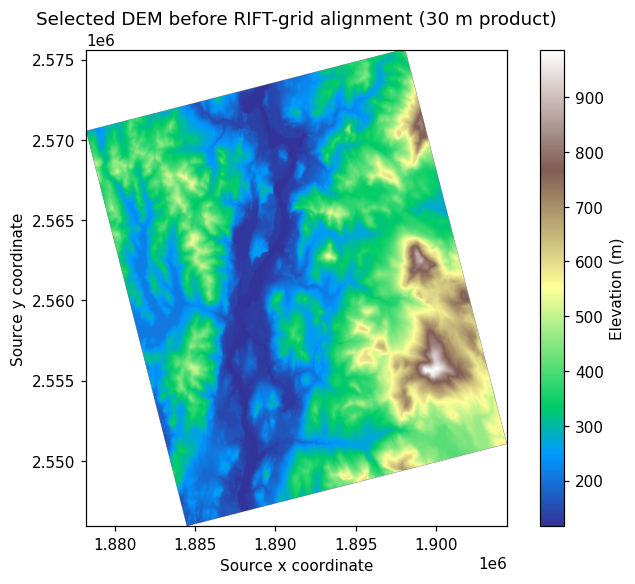

In [17]:
raw_dem = download_and_show("dem")

## Initial-state manager: save, checksum, and display the selected definition

### ✅ initial_state: `PASSED` — `dry_zero`

,check,status,value
0,saved native artifacts or declared derivation,PASS,1
1,definition: saved and nonempty,PASS,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...
2,initial water depth is nonnegative,PASS,0.0


,artifact,path,bytes
0,definition,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...,111
1,plot,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...,21746


**Saved, unchanged native product metadata**

<IPython.core.display.JSON object>

**QC-approved selected native product**

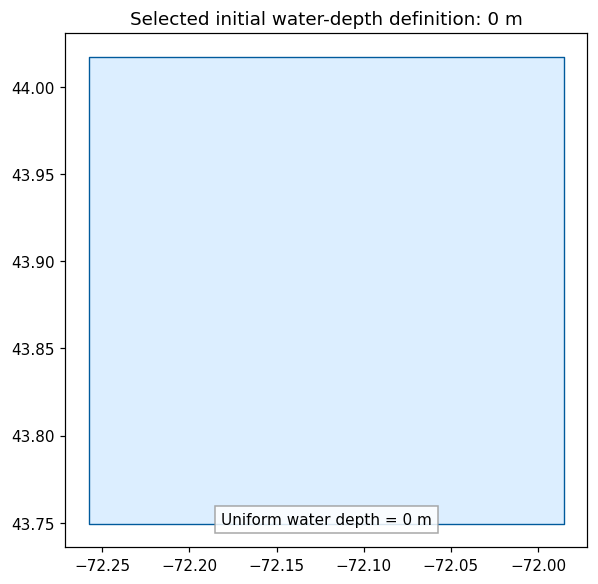

In [18]:
raw_initial_state = download_and_show("initial_state")

## Hydrography manager: download, save, checksum, and display

### ✅ hydrography: `PASSED` — `usgs_3dhp`

,check,status,value
0,saved native artifacts or declared derivation,PASS,1
1,vector: saved and nonempty,PASS,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...
2,hydrography: readable vector,PASS,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...
3,hydrography: CRS declared,PASS,EPSG:4326
4,hydrography: usable geometries,PASS,1088
5,hydrography: line geometries,PASS,{'LineString': 1088}


,artifact,path,bytes
0,vector,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...,1224704
1,plot,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...,146801


**Saved, unchanged native product metadata**

<IPython.core.display.JSON object>

**QC-approved selected native product**

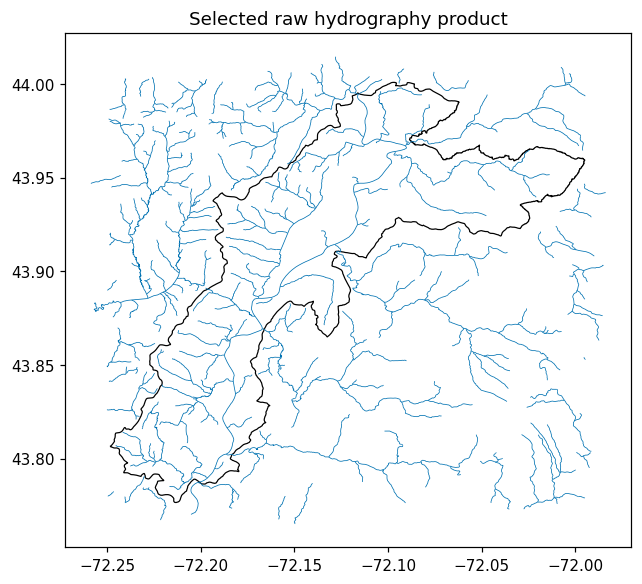

In [19]:
raw_hydrography = download_and_show("hydrography")

## Land-cover manager: download native NLCD tiles/mosaics and display

### ✅ land_cover: `PASSED` — `local`

,check,status,value
0,saved native artifacts or declared derivation,PASS,3
1,cover: saved and nonempty,PASS,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...
2,impervious: saved and nonempty,PASS,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...
3,canopy: saved and nonempty,PASS,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...
4,cover: required layer present,PASS,cover
5,cover: readable raster,PASS,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...
6,cover: CRS declared,PASS,EPSG:4326
7,cover: positive dimensions,PASS,"[2272, 1812]"
8,cover: contains valid cells,PASS,262144
9,impervious: required layer present,PASS,impervious


,artifact,path,bytes
0,cover,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...,1079342
1,impervious,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...,635894
2,canopy,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...,3305424
3,plot,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...,560901


**Saved, unchanged native product metadata**

<IPython.core.display.JSON object>

**QC-approved selected native product**

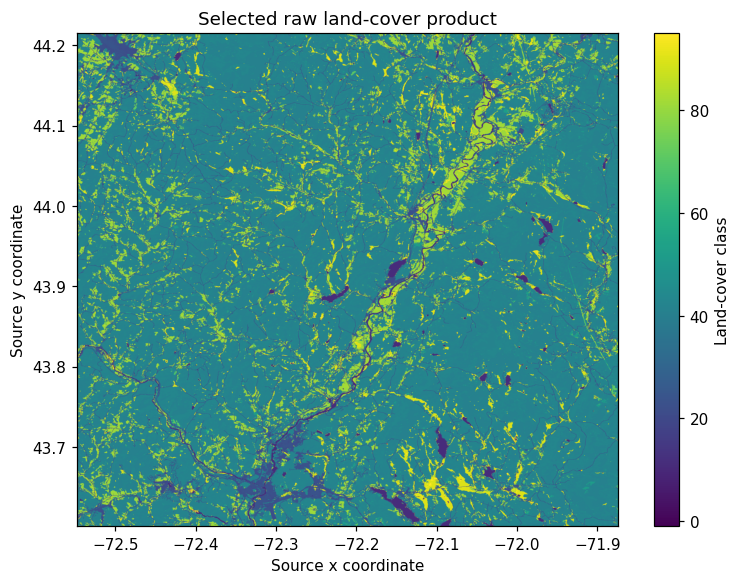

In [20]:
raw_land_cover = download_and_show("land_cover")

## Soil manager: download native soil data and display

### ✅ soil: `PASSED` — `watershed_workflow_ssurgo`

,check,status,value
0,saved native artifacts or declared derivation,PASS,3
1,tile_0001: saved and nonempty,PASS,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...
2,tile_0002: saved and nonempty,PASS,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...
3,vector: saved and nonempty,PASS,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...
4,soil: readable vector,PASS,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...
5,soil: CRS declared,PASS,EPSG:4326
6,soil: usable geometries,PASS,174
7,soil: polygon geometries,PASS,{'MultiPolygon': 174}
8,soil field: permeability [m^2],PASS,permeability [m^2]
9,soil field: porosity [-],PASS,porosity [-]


,artifact,path,bytes
0,tile_0001,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...,5169152
1,tile_0002,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...,98304
2,vector,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...,5169152
3,plot,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...,375201


**Saved, unchanged native product metadata**

<IPython.core.display.JSON object>

**QC-approved selected native product**

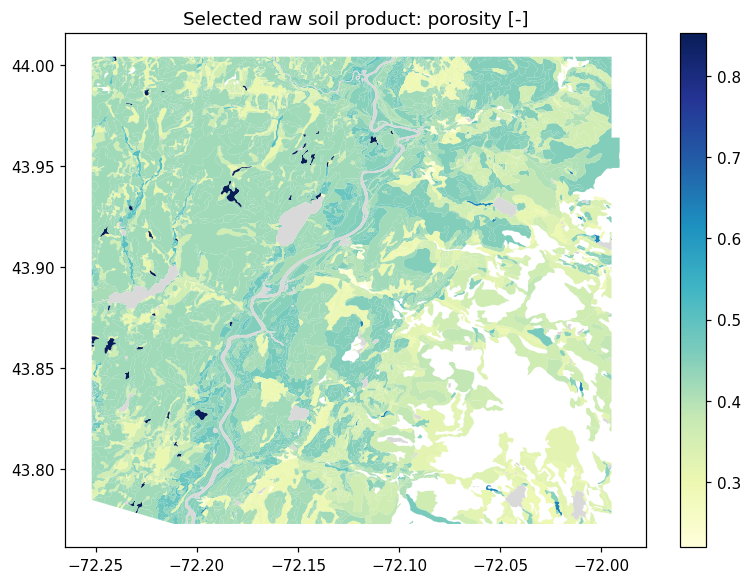

In [21]:
raw_soil = download_and_show("soil")

## Rainfall manager: download the original forcing and display

HDF5-DIAG: Error detected in HDF5 (1.14.6) thread 1:
  #000: H5F.c line 496 in H5Fis_accessible(): unable to determine if file is accessible as HDF5
    major: File accessibility
    minor: Not an HDF5 file
  #001: H5VLcallback.c line 3913 in H5VL_file_specific(): file specific failed
    major: Virtual Object Layer
    minor: Can't operate on object
  #002: H5VLcallback.c line 3848 in H5VL__file_specific(): file specific failed
    major: Virtual Object Layer
    minor: Can't operate on object
  #003: H5VLnative_file.c line 344 in H5VL__native_file_specific(): error in HDF5 file check
    major: File accessibility
    minor: Can't get value
  #004: H5Fint.c line 1055 in H5F__is_hdf5(): unable to open file
    major: File accessibility
    minor: Unable to initialize object
  #005: H5FD.c line 787 in H5FD_open(): can't open file
    major: Virtual File Layer
    minor: Unable to open file
  #006: H5FDsec2.c line 323 in H5FD__sec2_open(): unable to open file: name = '/path/to/WW_RIFT/de

### ✅ rainfall: `PASSED` — `watershed_workflow_aorc`

,check,status,value
0,saved native artifacts or declared derivation,PASS,1
1,netcdf: saved and nonempty,PASS,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...
2,rainfall variable present,PASS,APCP_surface
3,rainfall time coordinate present,PASS,time
4,rainfall has spatial dimensions,PASS,"[time, latitude, longitude]"
5,rainfall contains finite values,PASS,1521
6,rainfall is nonnegative,PASS,0.6
7,rainfall time is valid and increasing,PASS,49


,artifact,path,bytes
0,netcdf,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...,169413
1,plot,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...,35320


**Saved, unchanged native product metadata**

<IPython.core.display.JSON object>

**QC-approved selected native product**

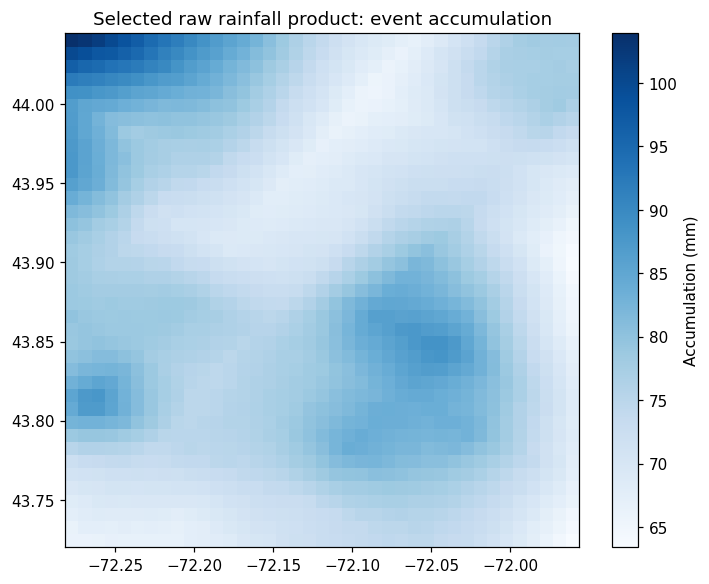

In [22]:
raw_rainfall = download_and_show("rainfall")

## Spin-up baseflow manager: save historical daily observations or the user definition

This history is separate from event inflows. All provider pages are saved under
`raw/spinup_baseflow/`; quantile calculation and spatial checks occur during processing.

### ✅ spinup_baseflow: `PASSED` — `usgs_waterdata`

,check,status,value
0,saved native artifacts or declared derivation,PASS,3
1,location_01138500: saved and nonempty,PASS,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...
2,observations_daily_01138500_00060_001: saved and nonempty,PASS,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...
3,download_manifest: saved and nonempty,PASS,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...
4,spinup_baseflow: stations explicitly selected,PASS,1


,artifact,path,bytes
0,location_01138500,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...,3479
1,observations_daily_01138500_00060_001,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...,4867019
2,download_manifest,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...,445
3,plot,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...,57010


**Saved, unchanged native product metadata**

<IPython.core.display.JSON object>

**QC-approved selected native product**

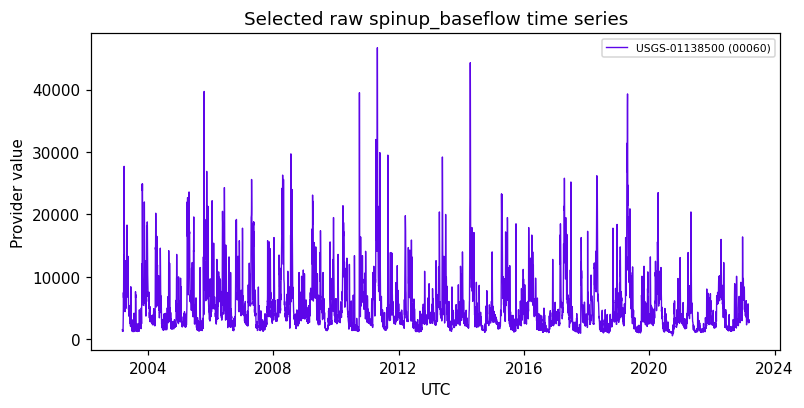

In [23]:
raw_spinup_baseflow = download_and_show("spinup_baseflow")

## Optional forcing managers: drainage, inflows, and coastal stage

**drainage: disabled**

### ✅ inflows: `PASSED` — `usgs_waterdata`

,check,status,value
0,saved native artifacts or declared derivation,PASS,3
1,location_01138500: saved and nonempty,PASS,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...
2,observations_continuous_01138500_00060_001: saved and nonempty,PASS,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...
3,download_manifest: saved and nonempty,PASS,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...
4,inflows: stations explicitly selected,PASS,1


,artifact,path,bytes
0,location_01138500,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...,3479
1,observations_continuous_01138500_00060_001,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...,139236
2,download_manifest,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...,424
3,plot,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...,30673


**Saved, unchanged native product metadata**

<IPython.core.display.JSON object>

**QC-approved selected native product**

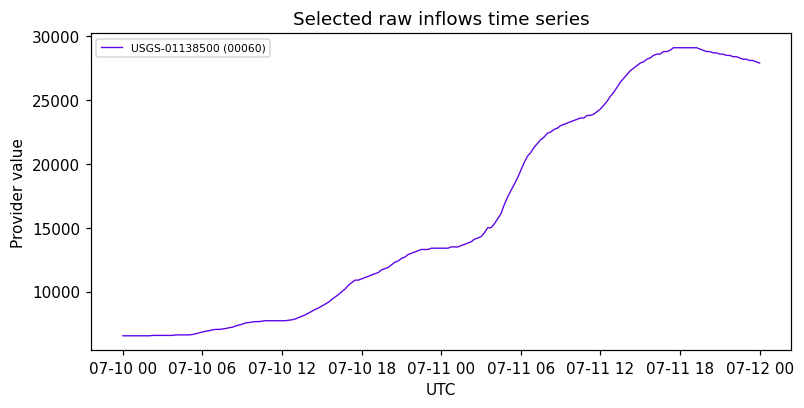

**coastal: disabled**

In [24]:
raw_optional = {}
for name in ("drainage", "inflows", "coastal"):
    product = download_and_show(name)
    if product is not None:
        raw_optional[name] = product

## Confirm the complete raw catalog

This cell refuses to continue if any enabled manager cell was skipped. No RIFT-grid interpolation
has occurred yet.

In [25]:
require_current_settings(widget_values, snapshot_widget_values(globals()))
downloaded = builder.finish_raw_downloads()
display(Markdown(f"**Raw phase complete:** `{downloaded.summary_path}`"))
display(pd.read_csv(downloaded.timing_csv_path))
display(JSON(json.loads(downloaded.summary_path.read_text())))

**Raw phase complete:** `/path/to/WW_RIFT/demo_cases/demo_huc12_010801040205/quality_control/raw_download_complete.json`

,stage,started_utc,wall_seconds,status
0,resolve_boundary,2026-10-28T18:35:27.157918+00:00,5.572589,ok
1,download_raw_dem,2026-10-28T18:35:33.025933+00:00,17.899292,ok
2,download_raw_initial_state,2026-10-28T18:35:51.472668+00:00,0.161371,ok
3,download_raw_hydrography,2026-10-28T18:35:51.686623+00:00,3.835816,ok
4,download_raw_land_cover,2026-10-28T18:35:56.018690+00:00,0.814247,ok
5,download_raw_soil,2026-10-28T18:35:57.331323+00:00,20.757166,ok
6,download_raw_rainfall,2026-10-28T18:36:18.610402+00:00,11.935976,ok
7,download_raw_spinup_baseflow,2026-10-28T18:36:31.045687+00:00,1.271442,ok
8,download_raw_inflows,2026-10-28T18:36:32.810389+00:00,0.664339,ok


<IPython.core.display.JSON object>

## Build and validate RIFT inputs from the saved raw catalog

This cell uses only the raw products created above. It does not delete the case or download a
second copy. Processing includes remapping to the requested RIFT grid, writing forcing files,
quality-control checks, configuration, manifest, and run instructions.

In [26]:
require_current_settings(widget_values, snapshot_widget_values(globals()))
try:
    result = build_rift_inputs(downloaded)
except Exception:
    display(Markdown("## ⚠️ Processing stopped at a quality gate"))
    display(Markdown(
        "Review the diagnostic report/map below. For land cover or soil, enter a user-approved "
        "constant in the relevant widget or select a corrected local product. Then rerun the "
        "manager-build cell, domain cell, every enabled raw-manager cell, raw-catalog cell, and "
        "this build cell. Select cache mode 'reuse' if you want to preserve the raw downloads; "
        "select 'fresh' only when you intentionally want a complete new download."
    ))
    for report_name in (
        "land_cover_coverage.json", "soil_coverage.json",
        "rainfall_coverage.json", "initial_state_coverage.json",
    ):
        report_path = builder.paths.quality_control / report_name
        if report_path.is_file():
            display(Markdown(f"### `{report_name}`"))
            display(JSON(json.loads(report_path.read_text())))
    for image_name in (
        "land_cover_coverage_map.png", "soil_coverage_map.png",
        "rainfall_coverage_map.png",
        "land_cover_percentage_over_100_before_correction_map.png",
        "land_cover_percentage_after_correction_map.png",
    ):
        image_path = builder.paths.quality_control / image_name
        if image_path.is_file():
            display(Image(filename=str(image_path)))
    run_manifest_path = builder.paths.provenance / "run_manifest.json"
    if run_manifest_path.is_file():
        display(Markdown(f"### Failed-run provenance: `{run_manifest_path}`"))
        display(JSON(json.loads(run_manifest_path.read_text())))
    raise
else:
    display(Markdown(f"### ✅ RIFT build complete: `{result.case_root}`"))
    display(JSON({key: str(value) for key, value in result.__dict__.items()}))

[riftprep rainfall] loading 48 selected hourly record(s) into memory


[riftprep rainfall] saved the unchanged event subset and closed all source NetCDF handles


[riftprep rainfall] writing staged RIFT HDF5 at /tmp/riftprep-rainfall-tfsux5qe/rainfall_ats.h5


[riftprep rainfall] mapping rainfall record 1/48


[riftprep rainfall] mapping rainfall record 2/48


...

[riftprep rainfall] reopening and validating the complete staged HDF5


[riftprep rainfall] publishing the validated HDF5 to the case directory


[riftprep rainfall] published /path/to/WW_RIFT/demo_cases/demo_huc12_010801040205/simulation_ready/rainfall_ats.h5


### ✅ RIFT build complete: `/path/to/WW_RIFT/demo_cases/demo_huc12_010801040205`

<IPython.core.display.JSON object>

## Inspect timings, provenance, and quality control

## Final per-input status

,input,provider,status,native_qc_report,processed_qc_report
0,dem,watershed_workflow_3dep,PASSED,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...,NaN
1,initial_state,dry_zero,PASSED,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...
2,hydrography,usgs_3dhp,PASSED,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...,NaN
3,land_cover,local,PASSED,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...
4,soil,watershed_workflow_ssurgo,PASSED,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...
5,rainfall,watershed_workflow_aorc,PASSED,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...
6,spinup_baseflow,usgs_waterdata,PASSED,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...
7,inflows,usgs_waterdata,PASSED,/path/to/WW_RIFT/demo_cases/demo_huc12_01080...,NaN


,stage,started_utc,wall_seconds,status
0,resolve_boundary,2026-10-28T18:35:27.157918+00:00,5.572589,ok
1,download_raw_dem,2026-10-28T18:35:33.025933+00:00,17.899292,ok
2,download_raw_initial_state,2026-10-28T18:35:51.472668+00:00,0.161371,ok
3,download_raw_hydrography,2026-10-28T18:35:51.686623+00:00,3.835816,ok
4,download_raw_land_cover,2026-10-28T18:35:56.018690+00:00,0.814247,ok
5,download_raw_soil,2026-10-28T18:35:57.331323+00:00,20.757166,ok
6,download_raw_rainfall,2026-10-28T18:36:18.610402+00:00,11.935976,ok
7,download_raw_spinup_baseflow,2026-10-28T18:36:31.045687+00:00,1.271442,ok
8,download_raw_inflows,2026-10-28T18:36:32.810389+00:00,0.664339,ok
9,build_domain_masks,2026-10-28T18:36:34.028691+00:00,0.152047,ok


<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

...

**Checksummed raw artifacts:** 17

**Run provenance:** `/path/to/WW_RIFT/demo_cases/demo_huc12_010801040205/quality_control/provenance/run_manifest.json`

<IPython.core.display.JSON object>

## QC-approved products received by RIFT

### Processed Dem

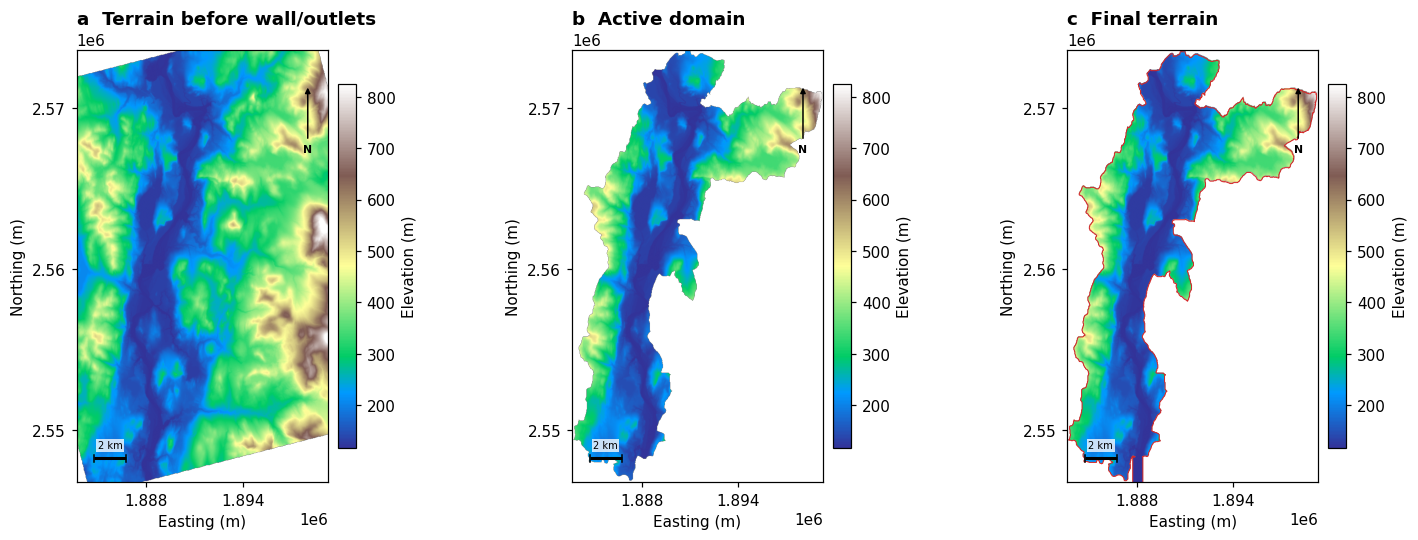

### Processed Inflows

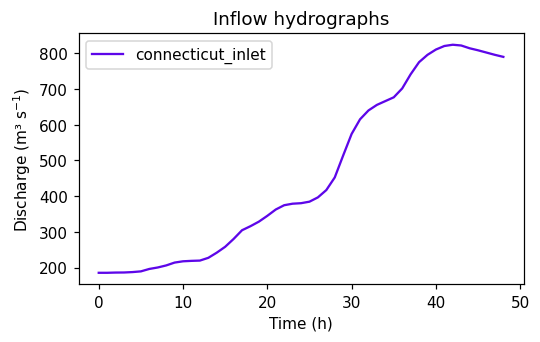

### Processed Initial State

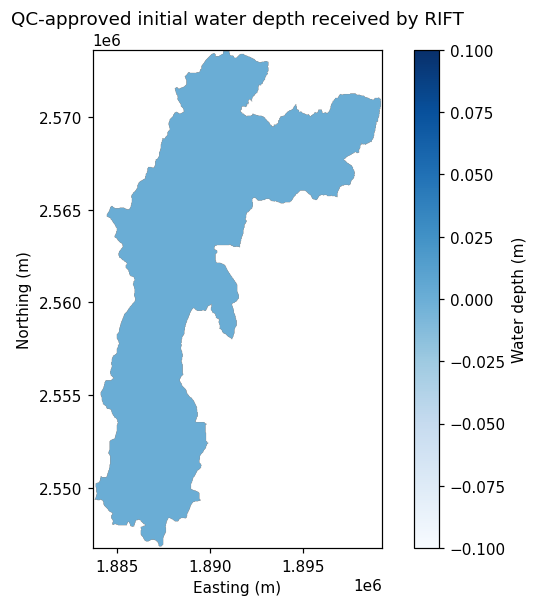

### Processed Land Cover

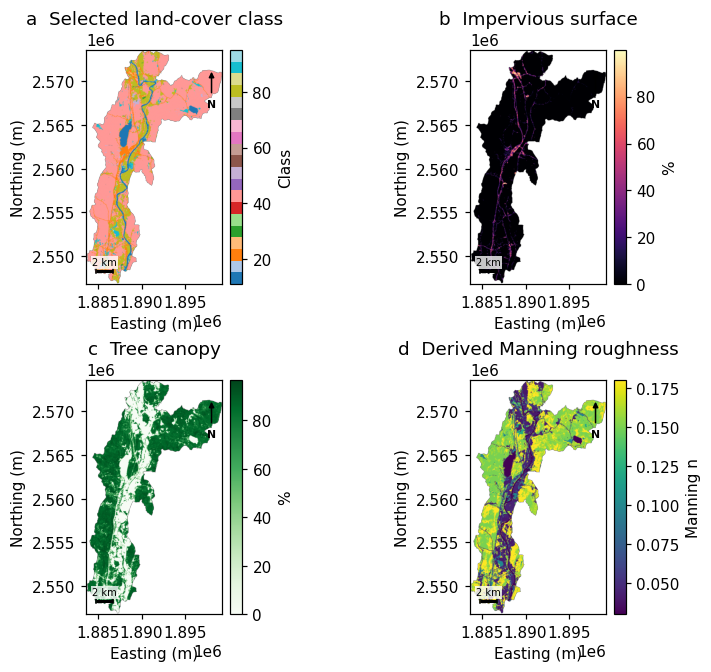

### Processed Outlet

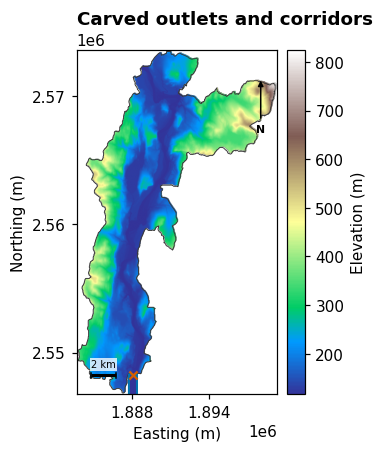

### Processed Rainfall

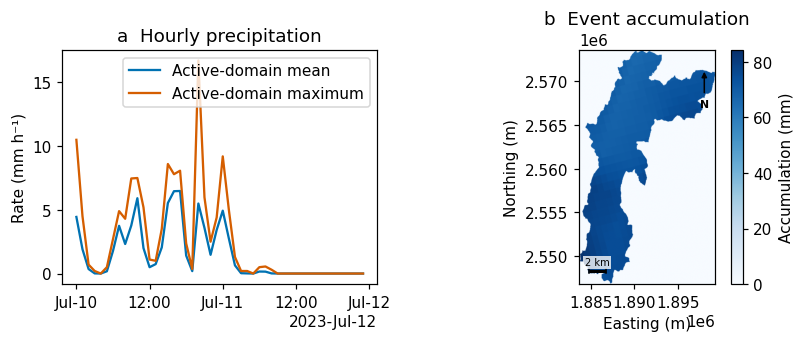

### Processed Soil

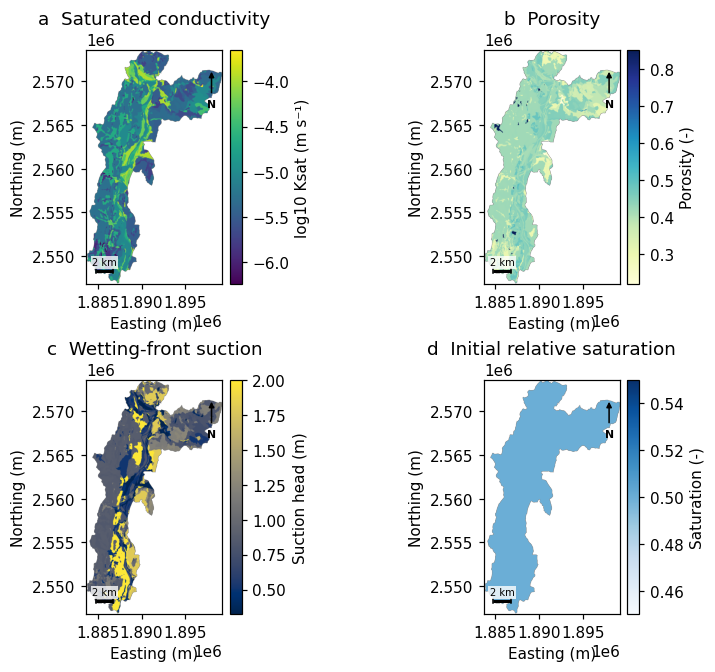

### Processed Spinup Baseflow

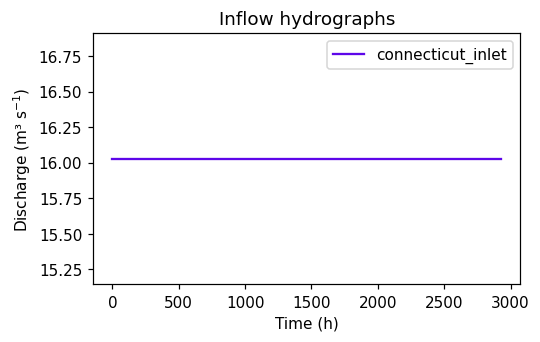

## Coverage and correction evidence

### Land Cover Coverage Map

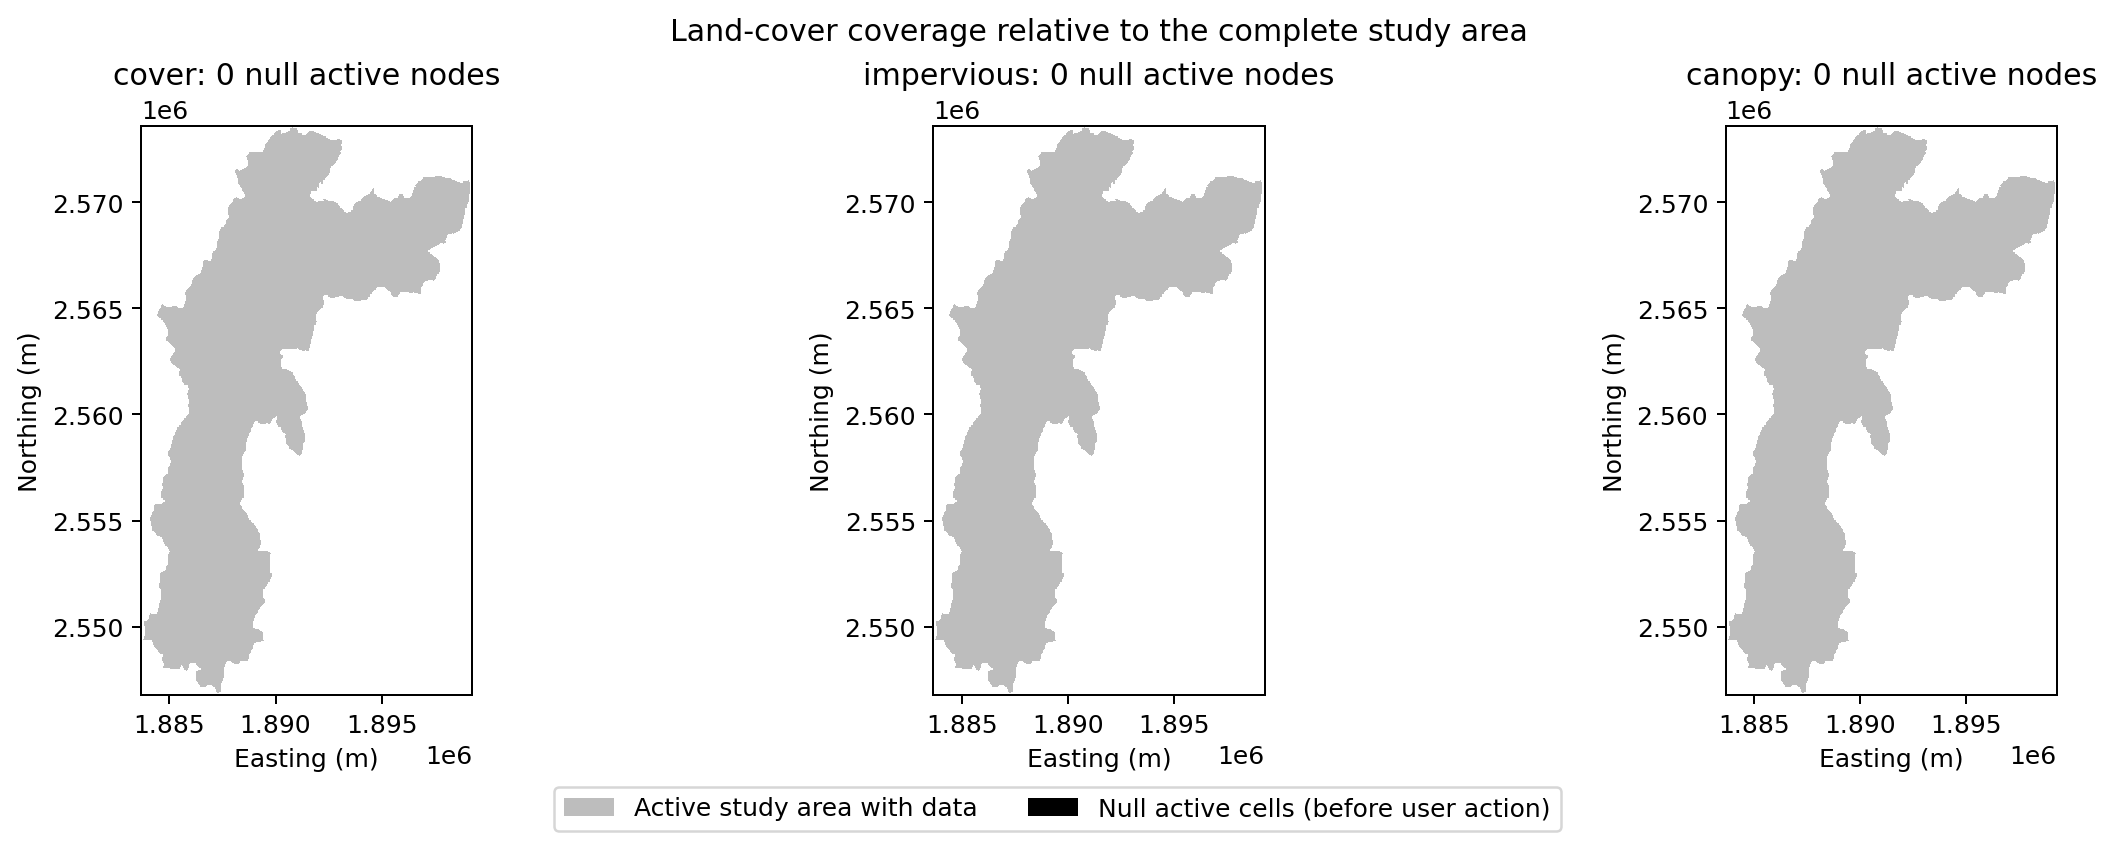

### Soil Coverage Map

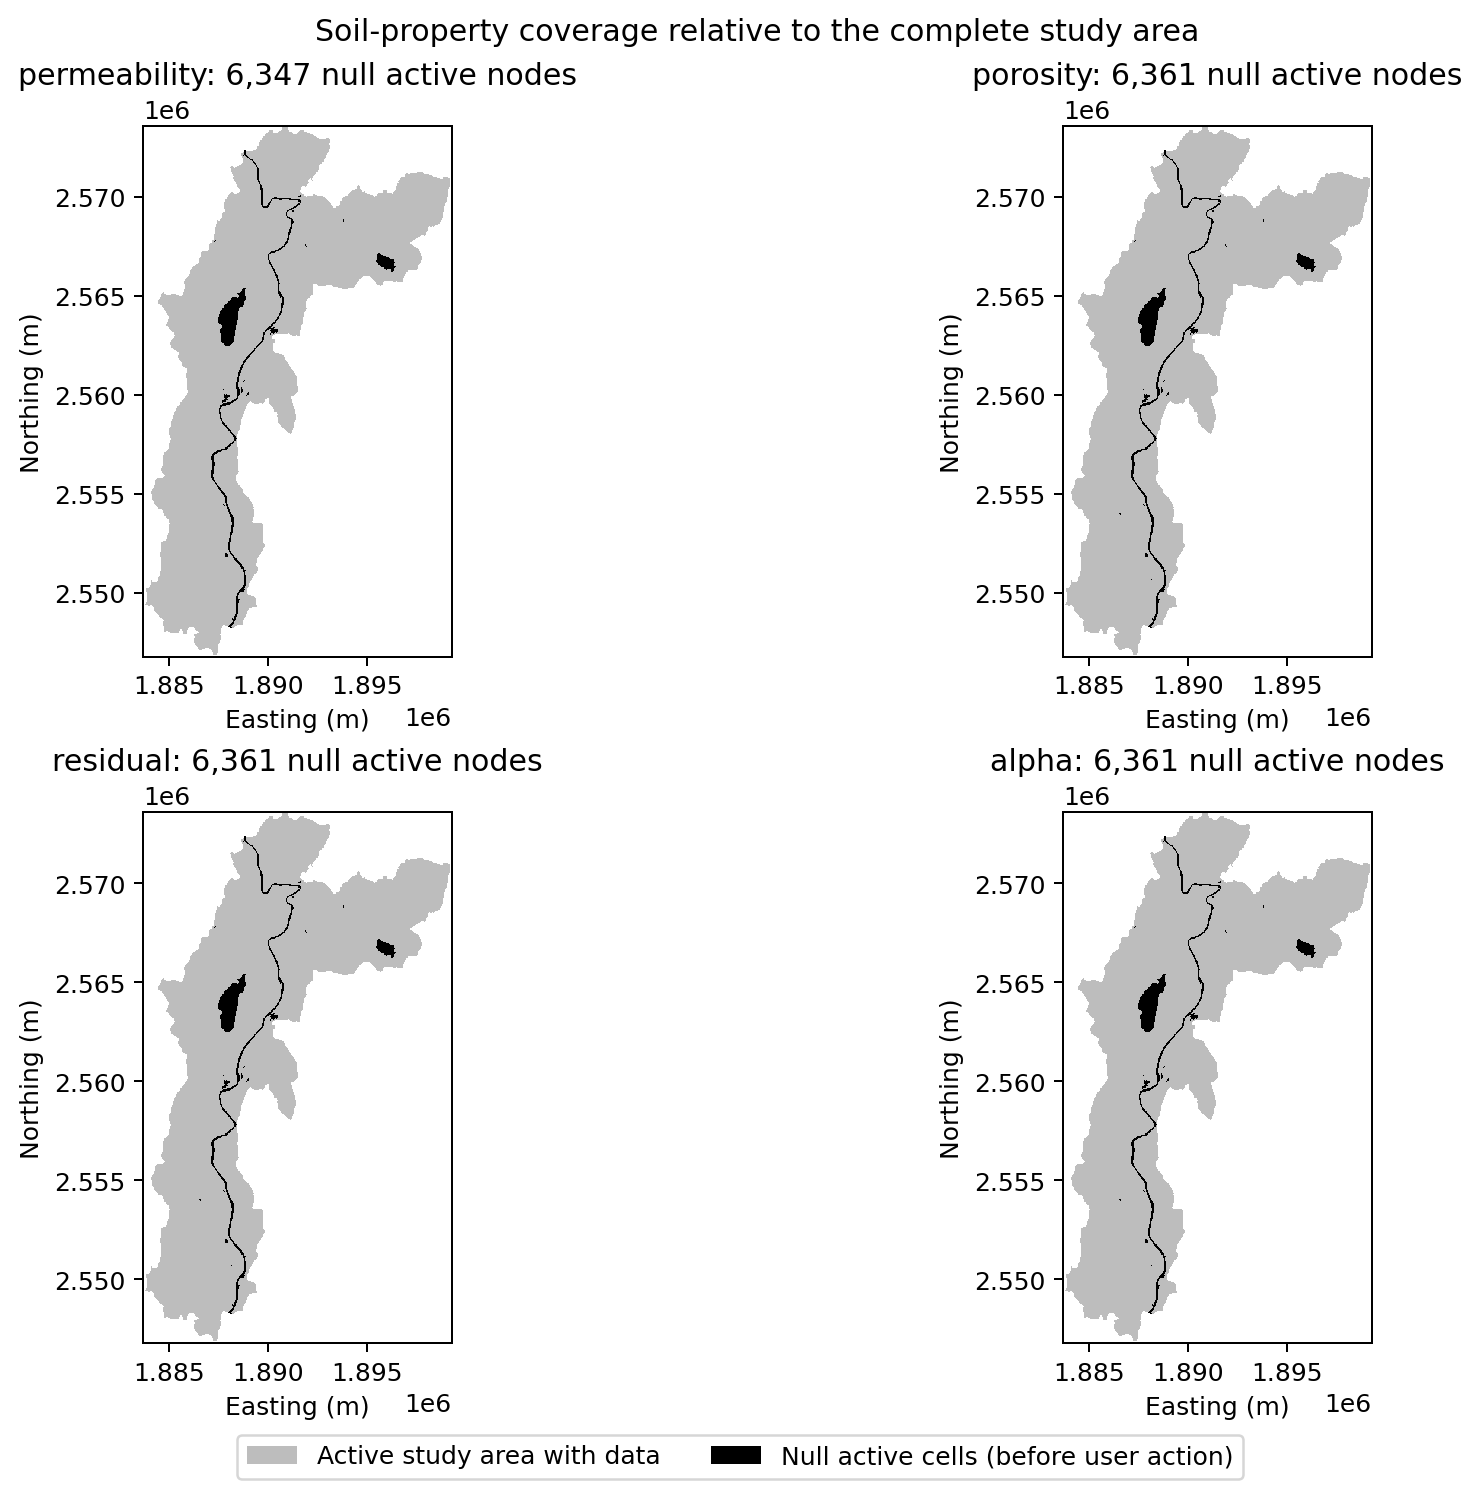

### Rainfall Coverage Map

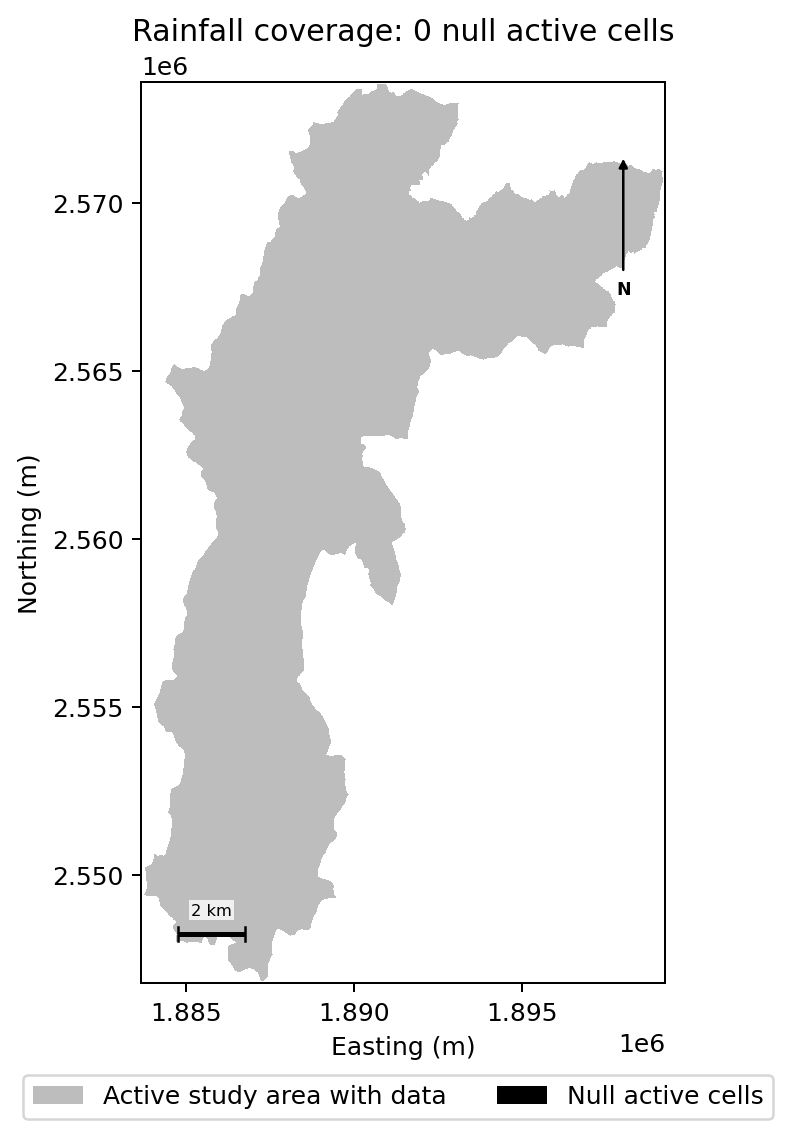

### Land Cover Percentage Over 100 Before Correction Map

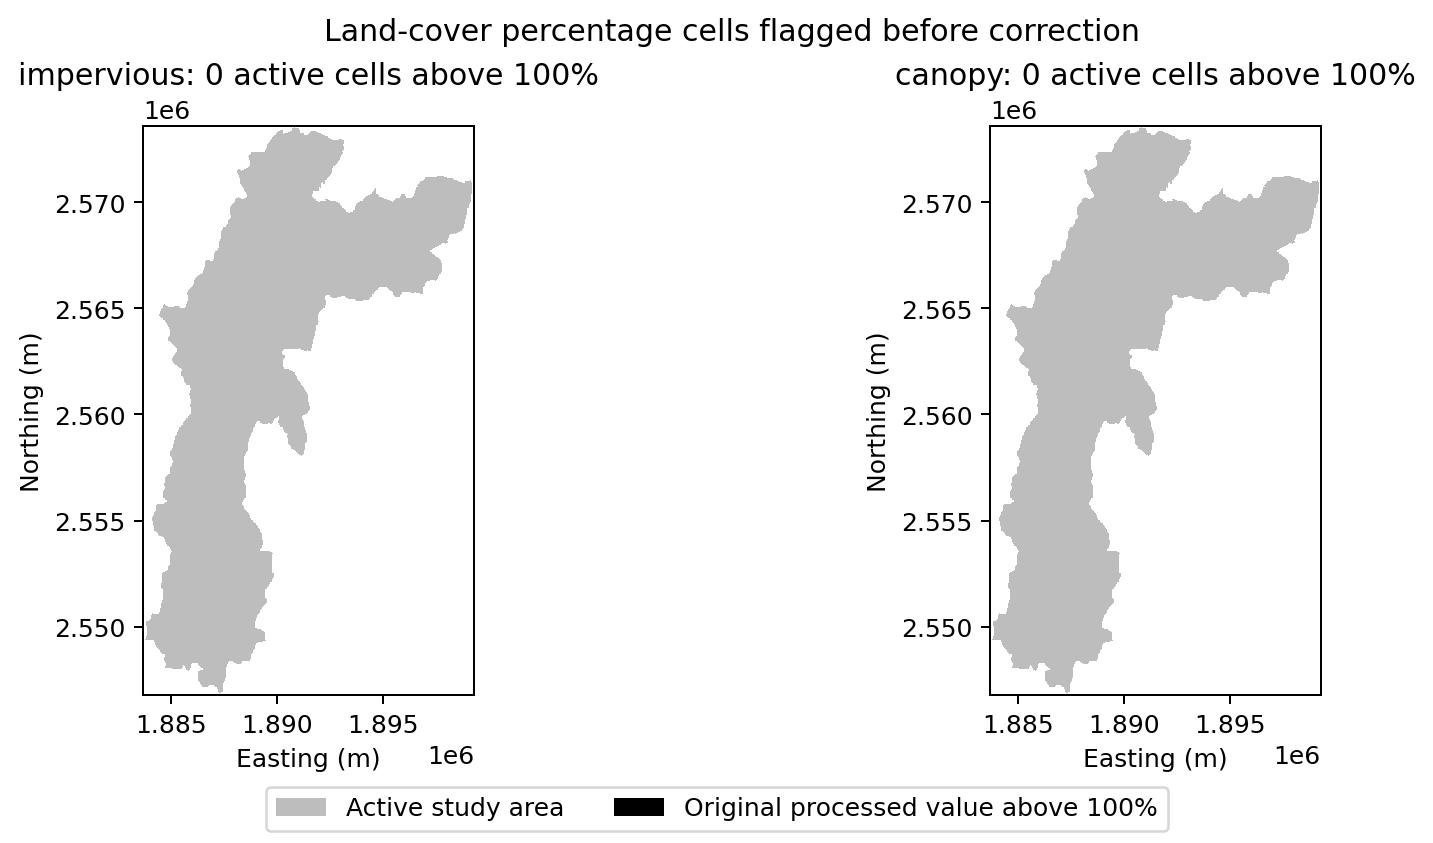

### Land Cover Percentage After Correction Map

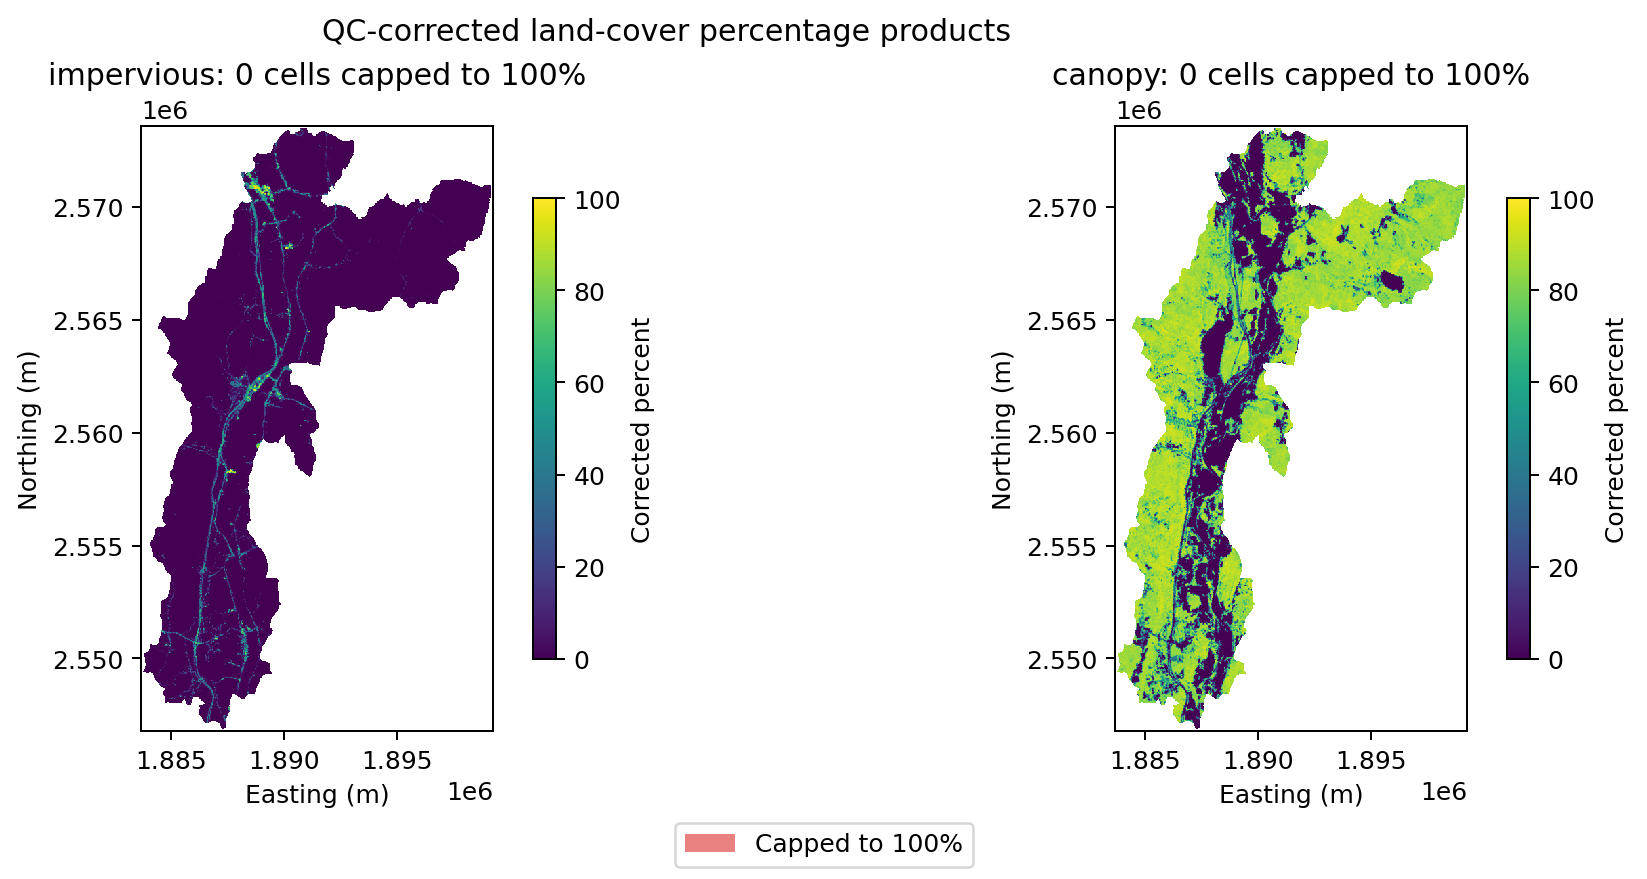

In [27]:
timings = pd.read_csv(result.timing_csv_path)
qc = json.loads(result.qc_json_path.read_text())
raw_inventory = json.loads(result.raw_catalog_path.read_text())
input_status = pd.read_csv(result.case_root / "quality_control/input_status_summary.csv")
run_provenance = json.loads(result.run_manifest_path.read_text())

display(Markdown("## Final per-input status"))
display(input_status)
display(timings)
display(JSON(qc))
if spec.spinup.enabled:
    display(JSON(json.loads((result.case_root / "quality_control/spinup_baseflow.json").read_text())))
    display(JSON(json.loads((result.case_root / "simulation_plan.json").read_text())))
display(Markdown(f"**Checksummed raw artifacts:** {len(raw_inventory)}"))
display(Markdown(f"**Run provenance:** `{result.run_manifest_path}`"))
display(JSON({
    "run": run_provenance["run"],
    "fallbacks": run_provenance["fallbacks"],
    "warnings": run_provenance["warnings"],
    "missing_metadata": run_provenance["missing_metadata"],
}))

display(Markdown("## QC-approved products received by RIFT"))
for figure in sorted((result.case_root / "figures").glob("processed_*.png")):
    display(Markdown(f"### {figure.stem.replace('_', ' ').title()}"))
    display(Image(filename=str(figure)))

display(Markdown("## Coverage and correction evidence"))
for figure_name in (
    "land_cover_coverage_map.png", "soil_coverage_map.png",
    "rainfall_coverage_map.png",
    "land_cover_percentage_over_100_before_correction_map.png",
    "land_cover_percentage_after_correction_map.png",
):
    figure = result.case_root / "quality_control" / figure_name
    if figure.is_file():
        display(Markdown(f"### {figure.stem.replace('_', ' ').title()}"))
        display(Image(filename=str(figure)))

## Output contract

- `raw/`: immutable provider responses/downloads, byte-preserved local sources, and provider caches
- `figures/raw_*`: the selected source products before RIFT-grid processing
- `processed/`: reproducible intermediate transformations not consumed directly by RIFT
- `simulation_ready/`: quality-controlled ESRI ASCII, HDF5, CSV, and boundary files RIFT receives
- `quality_control/provenance/`: source choices, sizes, and SHA-256 checksums
- `quality_control/provenance/acquisition_events.*`: successful, reused, and failed acquisition attempts
- `quality_control/provenance/run_manifest.json`: latest versioned success/failure/resume provenance
- `quality_control/provenance/run_manifests/`: one history record per workflow attempt
- `quality_control/timings/`: measured wall-clock time for every stage
- `rift_case.cfg`: transient/event configuration
- `rift_spinup.cfg`, `simulation_plan.json`: rain-free spin-up and explicit run order (when enabled)
- `RUN.md`, `case_manifest.json`: instructions and provenance; simulation is a separate step

For backward compatibility, a resumed case that already contains `rift_inputs/` continues to use
that directory without migration. New cases always use `simulation_ready/`. The resolved choice is
recorded in `quality_control/directory_contract.json`.

Provider metadata, redacted query parameters, acquisition timestamps, embedded CRS status, and
SHA-256 checksums are recorded for every raw artifact. Missing values are marked explicitly, and
failed partial responses are inventoried without being treated as valid raw products.

Always inspect the maps and quality-control reports before running the simulation.